# Exploración de Datos – Trabajo Práctico 2 (Individual)
## Selección de una fuente de datos, exploración y limpieza con una base relacional en RSQLite
**Tema:** Posicionamiento de precios, recepción crítica, modalidad editorial y alcance comercial de videojuegos en **Steam** (`1998–2025`) a partir de datos de **SteamSpy** y **Valve Steam Web API**.

- **Estudiante:** Tomás Velles Aguirre (`tomasvelles@gmail.com`)
- **Carrera:** Licenciatura en Ciencia de Datos – Facultad de Química e Ingeniería (UCA, Sede Rosario, 2026)
- **Entorno de ejecución:** Kernel **R** (`DBI`, `RSQLite`, `dplyr`, `tidyr`, `readr`, `stringr`, `jsonlite`, `ggplot2`, `scales`) ejecutable de principio a fin en **Google Colab** y **VS Code**.

## Paso 1. Plantear el problema, seleccionar la fuente e importar

### 1.1. Problema, contexto, objetivo, alcance y preguntas exploratorias
- **Contexto y problema:** El mercado de distribución digital de videojuegos en PC a través de **Steam** (Valve Corporation) exhibe una fuerte concentración comercial y una creciente heterogeneidad tarifaria. Cada año se publican miles de títulos que compiten simultáneamente con el catálogo histórico acumulado desde 1998. Sin embargo, para **estudios desarrolladores independientes (indies), editoriales (publishers) y analistas de producto**, no resulta evidente cómo se articulan el precio de lista, el género, la modalidad editorial (autopublicación frente a contratación de un editor externo) y la recepción crítica con la probabilidad de alcanzar audiencias masivas ($\ge 500	ext{k}$ o $\ge 1	ext{M}$ de propietarios).
- **Objetivo:** Construir un flujo reproducible en R y SQLite que importe, diagnostique, limpie y normalice en una base relacional de **6 tablas conectadas** un conjunto de **2,410 registros de listados de SteamSpy** (correspondientes a **1,638 videojuegos únicos** lanzados entre 1998 y 2025), ejecutando consultas SQL y visualizaciones en `ggplot2` para responder tres preguntas exploratorias.
- **Alcance:** La primera versión analiza 5 géneros representativos del catálogo (`Indie`, `Action`, `Adventure`, `Sports`, `Massively`) más el listado específico de lanzamientos recientes de la `Cohorte 2025`. Se evalúan títulos efectivamente lanzados entre **1998 y 2025**, excluyendo mediante regla explícita juegos aún no publicados (`"Coming soon"`), lanzamientos de 2026 o registros con fechas corruptas previas a 1998.
- **Tres preguntas exploratorias:**
  1. **Pregunta 1 (Géneros, precios y recepción):** ¿Cómo se distribuyen el precio de lista en títulos pagos (USD), la proporción de juegos gratuitos (*Free-to-Play*) y el puntaje de la crítica especializada (*Metascore*) entre los géneros analizados (`Action`, `Adventure`, `Indie`, `Sports`, `Massively`) y la `Cohorte 2025`, y cómo se vinculan con la proporción de éxitos comerciales ($\ge 1	ext{M}$ de propietarios)?
  2. **Pregunta 2 (Modalidad editorial y escala del estudio):** ¿Qué diferencias de alcance comercial (porcentaje de títulos que superan los $500,000$ propietarios), precio promedio y recepción crítica existen entre los títulos **Autopublicados** (`developer == publisher`) y los respaldados por un **Editor Externo** (`developer != publisher`), al controlar por la escala del estudio desarrollador en la muestra (monotítulo, mediano de 2 títulos o consolidado de 3+ títulos)?
  3. **Pregunta 3 (Evolución por cohortes de lanzamiento 1998–2025):** ¿Cómo varían el precio nominal vigente, la cobertura de prensa especializada (*Metascore*) y el volumen acumulado de propietarios a través de las seis etapas históricas del catálogo de Steam (`1998–2012`, `2013–2016 Greenlight`, `2017–2020 Steam Direct`, `2021–2023`, `2024` y `2025`), y cómo opera el efecto de antigüedad/exposición en tienda?

### 1.2. Justificación de la fuente frente a las seis condiciones de la consigna
1. **Pertinencia:** Permite responder las tres preguntas exploratorias cruzando precios, géneros, estudios/editores, recepción crítica y propietarios estimados.
2. **Fiabilidad y procedencia verificable:**
   - **Responsable:** **Sergey Galyonkin** – portal **SteamSpy** ([https://steamspy.com](https://steamspy.com)), alimentado por la **Steam Web API oficial de Valve Corporation** y puntuaciones de **Metacritic**.
   - **Documentación y metodología:** Disponible en [https://steamspy.com/about](https://steamspy.com/about) (explica el muestreo estadístico de perfiles de Steam y la API pública `https://steamspy.com/api.php`).
   - **Fecha de acceso:** `2026-10-21`.
   - **Condiciones de uso / licencia:** Datos públicos de uso libre con atribución a `steamspy.com` ([https://steamspy.com/about](https://steamspy.com/about)).
   - **Limitaciones conocidas:** Las cifras de propietarios se informan como intervalos cerrados (`owners_raw`) estimados estadísticamente y no como ventas contables auditadas; los precios corresponden al valor nominal vigente en USD en la tienda de EE. UU. al momento de la extracción.
3. **Detalle y relaciones:** Un mismo videojuego pertenece simultáneamente a múltiples géneros (` relación N:M`) y múltiples juegos pertenecen a un mismo estudio desarrollador (`relación N:1`), lo que fundamenta de manera natural un modelo relacional normalizado de **6 tablas** (`lotes_extraccion`, `generos`, `estudios`, `juegos`, `metricas_steamspy`, `juego_genero`).
4. **Variables útiles de estudio (más allá de claves):**
   - `precio_usd` (cuantitativa continua, en dólares estadounidenses `USD`): posicionamiento tarifario.
   - `metascore_pct` y `userscore_pct` (cuantitativas discretas, escala `0–100%`): recepción crítica de prensa y usuarios.
   - `propietarios_min`, `propietarios_max`, `propietarios_med` (cuantitativas, en cuentas de usuario): alcance comercial acumulado.
   - `modalidad_publicacion` y `estado_precio` (categóricas nominales): estrategia editorial y modelo de monetización.
   - `anio_lanzamiento` (cuantitativa discreta temporal, `1998–2025`): cohorte histórica de publicación.
5. **Acceso y tamaño manejables:** Los archivos originales ocupan menos de `300 KB` (`2,410 filas`), se procesan en menos de 5 segundos en Google Colab y se conservan íntegros en `datos/original/`.
6. **Seguridad:** No requiere credenciales privadas, claves de API secretas ni contiene datos personales sensibles.

In [ ]:
# ==============================================================================
# PASO 1.3: Configuración del entorno R, instalación de paquetes e importación
# ==============================================================================
options(warn = -1, scipen = 999)

paquetes_requeridos <- c("DBI", "RSQLite", "dplyr", "tidyr", "readr", "stringr", "jsonlite", "ggplot2", "scales")
paquetes_faltantes <- paquetes_requeridos[!(paquetes_requeridos %in% installed.packages()[, "Package"])]
if (length(paquetes_faltantes) > 0) {
  install.packages(paquetes_faltantes, repos = "https://cloud.r-project.org", quiet = TRUE)
}

suppressPackageStartupMessages({
  library(DBI)
  library(RSQLite)
  library(dplyr)
  library(tidyr)
  library(readr)
  library(stringr)
  library(jsonlite)
  library(ggplot2)
  library(scales)
})

# Crear estructura de directorios del proyecto si se ejecuta el notebook suelto en Google Colab
dirs_proyecto <- c("datos/original", "sql", "R", "salidas/resultados")
for (d in dirs_proyecto) dir.create(d, recursive = TRUE, showWarnings = FALSE)

# Copia de respaldo autocontenida (garantiza reproducibilidad total en Colab aun sin montar Drive)
restaurar_si_no_existe <- function(ruta_destino, b64_gz) {
  if (!file.exists(ruta_destino)) {
    raw_gz <- jsonlite::base64_dec(b64_gz)
    con_gz <- gzcon(rawConnection(raw_gz))
    lineas <- readLines(con_gz, warn = FALSE, encoding = "UTF-8")
    close(con_gz)
    writeLines(lineas, ruta_destino, useBytes = TRUE)
  }
}

restaurar_si_no_existe("datos/original/steamspy_catalogo_bruto.csv", "...")
restaurar_si_no_existe("datos/original/steamspy_lotes_extraccion.json", "H4sIAPzh2GoC/82SzU7CQBSF9z7FDStMhBYiLtzVitpEqLGIMcY003KFicNMc2dKbIwP49K1j8CLOYVA/IkxsrAsZnXuOTnz5dzuADzZB1ATymDMR7VDqJ2Hg24c9I+Dbm1vKUo1TQjj8qY88JmZvwg1VhAZZNMoK6ABp/NXiaQgkCOOK+N9jtLmEupMSc0SsfCvXfUIaYwFnDJRKPnA5S44MGRihstkuMYEvItgFZeTiBXxMcoyZmJMpg8dR5enOiuaqZo6ViN0PpfAdMJifDTE0pSrhbfttg8aLbfRbq2uBE9RppyVqmeIJ3nK528SWMKRDIO678PRDew3XdvxhHGCK41rALurGMIx14aUjhPKjdI2ruO6Vnve+xm25w+CsL8JbS815Y8qxv2lxfbzPh52+4Ory40G7o1mlnJOlY/8e5GtBx9dhJeDaBPqUabI6KqRf2lRMe/9zm+8/fDMAu/aUp2/QPfVxP4TwZM5E/DR/f/gC2TkfKqw9dR7vXCTifeY1nyGooBeLgzPBCuQql78utS24G8t6O/cvQP5TZeVvAgAAA==")
restaurar_si_no_existe("datos/diccionario.csv", "H4sIAPzh2GoC/71YTXPbRhK951f0quIiWJnQpLRWLKdy0Ep0rI0kK6Kc7J5QI2BEjxfEYGcAJsy/yTEHH1K+5co/ltczAwiS9WFWquKyLQqcj/d6Xne/QamXqhCqrHUu89SktbwspFhKq/FBiVpXJs1lbURT8ghhrJ6rUjg9L/WVzmRu0lVqTfHZa3yhS1lQcjD7YShcreTCVas0k7UszNykl7apzShzS1GYWqU6FxfT/1zQUzo6vZh+Oz0XRznDCItacaJqyRtTrkj9XFuZZXr9oaRkqcusKSRlpqR/z16fDm9OxPiCeIePJk5I0u6Q/t8o6tbAFnSl42quoTfnx7SiK5W9lTw/k1XdWDnaiJ12NYclRopJigNZq7mx6/dSzHjqrFrRj+oS5PfPjsTWqVlcWhWQh9lkaL7+rVTW8w9LEf52s5OjMtdK0H5Wa1PiZ75EEBqLR7PK2NoJ2h5vPxN0Ip3jM14NR1ub0LCy/J8u5y2N9pDOjNMhnsbmYanJaPRsPB7eYNYbx6yWOlfmXYMYEJ9VYIWoe7V5en6puwOALxZmgWntrN6pbnQyc7lQaa3rQqVW/hRO5gKLGSrNgtcIFHAqLRURTybD/jbTEWKPDZ9KAZnU6195Mwbo526Ey6pCSac4z3rItl56FWKH2mNMTk5O6FDQf/FnuPUx1Djeh6j8RS60j5jTJVXWZMpJ+zVB9kWzYl3jGKSjwQETn5Mzphy0wncky/WHhSzwKRkcqox2JoIme7t7gw01VFmd9Ri9mR0CsI94hD+rDaLbJ3FmVabDQbMQyC/2NR/AJTaFEEDKcVDy9YdCWsUQP5/sjfYATpA/FEdzK+tG88Bk8NIqNRiCm2wcIuInnD7d35SKy4A05aS45nNmbIYl5TsvkKpRriP2lLh+ZVbXOqMl8v6a4oFcVBC1L6fG1503Tlm/PlDytPCZ80RRJS3SALA1gKt3IxrsffWEkr3dJ8MBcoSpUIL/hiC0CR/zE3LLXXM5l2WQb9YwJSemrtYLGVJYcUqu3+NJ1iOydQRcdomVeQAG534BqK3SYGF1OKgQEKfAhEegONFgNBpENhMxHo/5H41GtN3+srHQCrkCgp7WXr16gXRJFirXspTXxUlcaMXxB9CQwW8hs/UHCNUg+oDLql//UTAfR9vAvZCcKUnWyDL3TNe/Uq5dZUqNDhmmoCQgRJudQK5QlU2l7CcXIxxJk2uTuCHgI5/RdgtueYnyT7LCR9hFSOiHKAf1+res5GPjwlWv39dNYTaCWTWXyMS3m8BcVMhLVK4cKWglJd0Sw6jYAcVolgYw5+iwcTCXdmXxtJXL6LNzVUCFxoOdfX+sazX0BsKlbRtA+2sdRexSlJx9NxQHhVyyHHGScDPiwJRhr6DpFS2iw3DeRtxyEes/SpaE9wDwCK2hiIaA49+Wet+Ng7f4RLSNLfrugE5f49+b42PB7uPVxcXZrHM/LmZUpoAODUhMS2wAA6Osh8oKvDYILdq+7emZhrvhYSK6rIs/H41i1+p8nvsOeH5f7Iquh5uuryObCsiQB4TmuTAYaMh20B6BaRtYUl6Fa6u5FcGe0bobKeg4DzREp0PjG61ylVz/bopb0DPzFo7K12IJnGyv0EZWXLtdU6BY3o1YhXR17YfHQnuu5kjb82eUlMai/epfAsghKu1D2ozL36wJ1K2BmCcTsf183A50XFwfBIyiBFOcKpfBBNyK8NQ/bN2fOIQQlx4FoktJywGYu0izgWsxOjUHenbaXCO8pGO5WnD7tPIFnZjSxEIF4GjqJ76G45dtrh9IY2eK0DyTnS/u4xKcQPjxiYHfpSRXeVMVrToeC/wNVxsn5ibyuYSj68sLZ7C78zw6lEdQwxyYtOfiOve9D3Vi70KVOfdXLLq39/xLNvrDlsWEkuDihuKHeIvzN6F4ADV3PyuLF8RK99WFq3ObD21dCTRCaU8OXk0PvqN/TS9+nE5Pibek/dNDf7+4p+RFHpU3c2njcnE+3T8Wh61n84bC8JVSlY4tGaxhx2AbHcNPBIWtuzhw84CNlzWUx0lY67KBcMKkti/hdObs95gHG89kPILJwC+dORRe0HDIxP7p4RMJgNOwxe07HbHZuepL6QaFQ1Q+mGxcOwdncm4GggbfRgxwQZ97XEuUKp0b9qmDmbfsnkvkgGEMFbmgluDNnRNRm0vLpY0tjnEPw0eNlT5n0u60zUdX09iDccvplaK2JjwNX6p7ZJXxKt5G4SAG+zAPcaOcOcLq0DffsNKGtMStYxqa/TQ0+zjgH2HA3YJCr+a1XdpaFX4SjHJaZfX19bTx94MqOPMGmQJxjb+cjMdPOn39k/dz0YDfQ6enMAirCSYfA3AsqgqpktnrxtEz+0krqpK9rlN8N7hUll3DJ3PrW+gUau7oHQRzzkga1/jvW1Y7lFjv4fuTUeoMLlG6vEJex3cjunPtH5n16OJ9/B5xDY+Blj//VdCuqf5u0CrWqTsQ4yohbRZeCqGxqeEjFB6tW3gui0yWWe/tQpCaIZ/SD/N+oO6mwSqJra75UefttvqNsLu1Stj3l11f7J5eN8YVnX8lti7825qq8WX19MWJf5Xm+zgg+ovTttiZ7JDkt4Mem3LdRcvBIUdLxd4JDiC+YfKvKGL3tP71TngZGaahrv0JxBy1sqMUAAA=")
restaurar_si_no_existe("sql/esquema.sql", "H4sIAPzh2GoC/7VXwW7bRhC96yvmZhGQHcmtjcSuAyjS2hUiS45Et8mJWJNrehuSyyyXgZ2/yTGHnnrrVT/WWS4pkhJJuKgrwIDEeZydnXnzZnx4CBcv+OkdHoJ9cwzkMQ6EpC7f/BWBx2BKlUjgEObcZZHLqUolBRbBhGc/S0j/djIewPHw+NTSvsapEvIMbBFuvifwGwsClsDYT7mULLNL94F/FWeQfAleseRLykJ6hN+1bcoSV/I4i+EMiDGCZAGGJSIaQCRkSAP+jXpCx7L+MOeKQf8UFL0LaFJCPZpk0bxopno3q/HV9RjuhWTcj5zP7CmBC1guznu96Wp5A/b43ZzA7BLIx9naXsMfKfOF47OISXHeDAmZktyliZMoRsMkfjrvcJW0GFmiUo+3mk0AbdZAKJY47FFh8XXu8DKYuNER2Dqnus4YIyZU1xp/xFK4zDMceDIv68fF+1i53mRFxjbJD9p1D/0e4Ec/drgHNvlow81qdj1efYL35NMgs0YivJPM0SCDWCzx73Y+h9vF7MMtMaj7lEXoRbIkFlGC0e6ADSqVgSMkxyQ0We+Z+0Cr4dWPm/xKJu+hH7DIVw/9XbCF1R8NLeMpyBul6RTJfJ4orIFzJ1OdyNnCJldktXfQHvAtDK2eZWpyfAQTqjbfA+ELnXN/8yMrLNbBFVIXgmKTbP5U3DW1WmtOreOnekVyOuSFML/aS+EKjyOJC3p2lCMvmnHYgfNlGgtHh8p1pE358gohEFFbSSW7Z7Ih4UWyftpJVtEj2jeVUgQBighSp6opST1R21dMpvKfOlVF+dqIm0M7koA94YqA3qHkKpTDVkLs46A/HMDIylkXCg+D96jnPNA7rlIUyUYGN+C0qwMt13F6h+TF+x8M4IB4HAUcx4FiMhIHxTkxk/c8wIu5NGikuBKKBo5C1wGyN0wxBTgw2q7VjH6L7bRl+89HQCKlQ0bN4VjoGGPGQn7lHhNGDmHzd5RxPSNTQwVzmKmfUeOu6pl4Gm+XWZzq/OnQpUwmAhp9oyFOSyWeISoVdE1VaISMq7pqy+ge8B2xfydkAaM3b17DeDHVI/rEGrRRuX5flrHAKRPfkJOSUjmB2vWzGfrvCCgZvuSkiQdY4a3nyuPZ2py5XNUeI6mG2f0rz365gJPh0Npmw/GxvVKuOvuwgqn3IGYTY3eM/+YE1CHZxW+on933Knerv695lIeJNPf1dNvePxuYZo5txbpej8vlisyuFprO2YF5hS3M1yVZkcWElJtCzb5cwJTMCXbNiqzt1WxiNzisn19zujvi+/lwb/JcdPdJdb/Y/DBLELgpxZZXWupoNsEwF8zsg+DKbLLprQN3kJjjUiIzcTZLn4aMzkY4r6K87a26FuxtWrks5M87hWFPOhr7Xu9JCU5i5sSu2kKLFqgbK1ytW7Ztm3F2VLJUYVszZwtul9Y9XJ2tkka+ZmKZQkdh7Rplr4YKedR66B5Qd53V5IQ+PtMJAtHJnmPTybvAlsNYLhbdJyGqdJAwP9T6WctQU25qG2xHJxbcqbWMYWjFVnbKZLyejKekrQVfoPdOi96LswUaFmfX+N+UkvXZ+rTdL1+54iHbLxuGa7Hu9bv7ZNC0a+7syDT6zCPfQX0JeCaX7VvyPjRbHUo5Nwfh+Ap1/TpVfQ9ab5eOMldkoizzoLyl9b+yoTym6ipf7qvW58v7f+TWP8uv9MyaEAAA")
restaurar_si_no_existe("sql/consultas.sql", "H4sIAPzh2GoC/+1ZS2/jyBG+61fUYQFLuxIt0Y+NtZkAWknrVSDLjiXPIggCoU310HSabKVJGp75N3Pcwx6CueWqP5aqbr5F2bLjRRZJ5uAxyaqvH9X11VftTgfeveG/RqcDiysbxo9rIRVzvM2XAFYcRiySIXRg6jk8cDwWxYoBD2Do6cfcpHkzHLTB7tqnLcIaxJFUfVhIf/M5hPdcCB7CwI09pbj+rpw770H2Ify7OHRkEMYiYqGFT/R1xENHeWs9iz7MuRdCZgPzP01hJZ3Y50HEVviiyQImNr9EnoMPH2lKaBwpKfSvTHgrttKTKv0L5a3iwAX4csWFBMUFLlsiFLmdQsRuBeLhWnFAL+IWIbzplhPgX4aXs/nNdDFY9v5Kz1eKuzGuC3p9uJKhp2fk42ZHkqa1VhzfhG2crcPN/oCjzNpx6Uw4LHDQTCpwNz8HXMlD4YW4TVJP/yagvSAgFmw+4xfcWHwQDD54+ENxvcVBxPtoWkVAS4HbGaGjdPVs5hFn/nz9UWMvzH7FkSe8TyYux+kmYjzgj5eTWasPLidMXMF9zF25NI/JE771eaQojsuQsEPCno+n4+GiQTFzrUD6GLbEDQbzBK+dfHZVvJZLOg8ebok2wBkjtPJY9poZ6+HlzWzRHE3mi8lsuIB7y8zIW7XILZIRE8tkWtp+fnPRHA7mY/jpx/EMzXm4dBUmhIeheQc9WNDrHoynaNKF8WykcQxCZplgXePYo2av27W68PVrkA+fmH4benrotRNVxzVO5bEotktzsHC0gyvmyoNsyPIq1ox+YjQT++JiBu/P9wa+t8zrZRyu9BjIHGbK5rXPV/jTjIYm1WF8C48JCx2JJwEXmS248FbJBMOJtr3x69pDW4WpRGPRdmIsMBjZ1lUs9H8ectjz4avCs0f4wzsNj//+nVDyR4rjsucjZtj44fryIk0mcBuT2Wx8rXOslFhw78LljBJDPyIkRuK+8LjlGMI9eaBNOgnyyB6K9lu5Cr52LXr6uec57toVfP/n4mza1ZRubydx4/J6hEOi486owGg8H35XIVS7TKh2n8oK99d88w+JjORzhQVMIGvWcWnI3c0/A6oNpn4AjhYRi5ADVicmmOZDPOUxzuOl7DrENXtBUmab2SjLdXwrcHhifXiENVfoudwerrWLcY9qGDfxCfcl2Xurdj7m5HOrNKlaJuVWMmTKpViUIg2XTaXgVsu7kRfFokyWvyl++W2Ry8mz3LKDUsIYo8mW6P83osy1YZWUB4q5nkYOuEnxPMK49cWAvwVB7DqB1dOXM8MOD1znsF0+UrVUcVSmiqM+jB+kiE163qH82XyhhWhd5cg7qSJuMjv4lIoz0om0Smj2zs5+10EhfNJ6OSsY6LWIkWmCmIlD/XPXWC9hgZ253wYhI1Qc/DFC3U+7VmIDOnuNVDMnqccCDHVxQt+PFz+N6fDh0mEwG2Ef0LPNeTzoWTCO2JrBUGArQLuY7lDPbh3sDY3mRyn0aQJtW9SvsCDUcTpXnAfCc+8iaJI1jXD6shG+TUawk2Q6OEonb2I78pA/DPy3FOLui+DtXgp/lMAfW3DBVrHin0jsRxqS0O0e/Xq0B/o7gjtO4E4smObfQrhGssPfsD4S5nEBTnPEwamVHblZzB+YNjtJzJA/NHcbg+KgT7B3xvRV4exbEfoScSYUWpSVJCizD7tIsAbhGXZz5C1X1LDWg/+/oPwnC8oLa0PBs0pXIIwjvV+iREMhadyFeVWsLDWnOS8iNR+pgFSLxbEuFsPkPgLyywc4pguPNfRO8nJJDIwE7vMAH7AfRktdhZDCkfz9GA0Va0PoBbCK11S3FPibn83eFPv48BUNfDILtAiZUlIIPN9K36RIXSrlrgJyUiwgYXybXr7ANy8QldUWP2lWStWFp+o/wUtFZl7N79gtFm4m9urZTYlfxgG2DWG9R6H5aOX3B+FyhVXeC6Jtzbl/s/nrkkuFVjIqb5rtNBxpb7NFZgilXLTz909npa2zyy7lZf6Uo+BCr8dkuFMapsSVcJeZwTaBMSf2YzqqmsSEDHjS7eYadFfXysuD37+NLn26ty55FdrmolvWpyetdbEbLzbjGU8VF9LezpLaDGn8OHg/mZ0/lSNI7cc72umaXddSuV1z0PWHxnRyMVkg2VX58WQnP56UWvCkxUb+8yXQLD7QTKBJlBg7+qI5v/EkwryZj1qvYMHqABJ4ep+ZoD8rqO2XCOpn5fMWF5wnl3QHuWT+AcVsJ5KdK8E+QvMrTJgarbkFNMcykjw9UB2MeAqJUq/wcaV1LO717HCwDVtgo99jwlrdgtzGDdh88elqVU+qBx346sw6O3sGxc5RSFJjQ/U5WGGpmwQrjyMUjdIlrN4eYMc5GAroCa5SmWM5GCCUnUIdVaCM5kWNjH2e78U+stFAexBe95uy7NWHpnTLub/eLeutbb/DjLPNt69bRWouS1iGrat0t0pLcUeq5SK7+zRr+O+4P30LRfpmYjSj6eIpyXm1+LZOQJ6WCbL271Vw2odBrO8cN79oGxQn3FUZ8bmKu8n9ITGdWcesfwEfafxPWBMMDklIksGa2t5zJEFiYifGBIyIgxH3g2B6EK4UwuEGEHEQm4axn3BwHhCUquRFn5CgzR/RSlVRS1meitldjJr9fW2V/QUOObUq7Z9UlxUJ+qTOJEqd02rwdBP1pTPnJn0BC5G+mUgOR/2haB0kSSKRdDFODorNJ7iBahEu5oGJmNa8j4BN+uGifjWpYhrgXXmXCiqNQZFZli1LKuptm7FX3Qu+ooO7mU3QZDCdlqJqJ1H1AnSJWVaedSKUD2I5tsUT82xY3f/BuP66Qve7xr8AiFjy/b8gAAA=")

cat("Entorno R configurado correctamente.\n")
cat("Versión de R:", R.version.string, "\n")
cat("Archivos originales verificados en datos/original/:\n")
print(list.files("datos/original", full.names = TRUE))

Entorno R configurado correctamente.
Versión de R: R version 4.4.1 (2024-06-14)
Archivos originales verificados en datos/original/:
[1] "datos/original/steamspy_catalogo_bruto.csv"     "datos/original/steamspy_lotes_extraccion.json"


In [ ]:
# ==============================================================================
# PASO 1.4 y 1.5: Importación de archivos originales (CSV y JSON) y Diccionario
# ==============================================================================
catalogo_bruto <- read_csv(
  "datos/original/steamspy_catalogo_bruto.csv",
  col_types = cols(.default = col_character()),
  show_col_types = FALSE
) %>%
  mutate(
    ranking_origen = as.integer(ranking_origen)
  )

lotes_extraccion_raw <- fromJSON("datos/original/steamspy_lotes_extraccion.json", flatten = TRUE) %>%
  as_tibble()

diccionario_vars <- read_csv("datos/diccionario.csv", show_col_types = FALSE)

cat("=== 1. METADATOS DE LOS 6 LOTES DE EXTRACCIÓN (JSON) ===\n")
print(lotes_extraccion_raw %>% select(lote_id, nombre_lote, fecha_extraccion, registros_brutos, url_origen))

cat("\n=== 2. ESTRUCTURA DEL CATÁLOGO BRUTO IMPORTADO (CSV: 2,410 filas x 11 columnas) ===\n")
glimpse(catalogo_bruto)

cat("\n=== 3. DICCIONARIO DE VARIABLES (datos/diccionario.csv) ===\n")
print(diccionario_vars %>% select(nivel, entidad_o_tabla, variable, tipo_dato, unidad, origen), n = 30)

=== 1. METADATOS DE LOS 6 LOTES DE EXTRACCIÓN (JSON) ===
         lote_id                                      nombre_lote fecha_extraccion  registros_brutos                           url_origen
      LOTE_INDIE                 Catálogo SteamSpy - Género Indie       2026-10-21               500     https://steamspy.com/genre/Indie
     LOTE_ACTION                Catálogo SteamSpy - Género Action       2026-10-21               500    https://steamspy.com/genre/Action
  LOTE_ADVENTURE             Catálogo SteamSpy - Género Adventure       2026-10-21               500 https://steamspy.com/genre/Adventure
     LOTE_SPORTS                Catálogo SteamSpy - Género Sports       2026-10-21               450    https://steamspy.com/genre/Sports
LOTE_COHORTE2025           Catálogo SteamSpy - Cohorte Anual 2025       2026-10-21               450       https://steamspy.com/year/2025
        LOTE_MMO Catálogo SteamSpy - Género Massively Multiplayer       2026-10-21                10 https://steams

## Paso 2. Explorar y diagnosticar la calidad inicial

Antes de aplicar cualquier transformación o limpieza, inspeccionamos el estado original de los `2,410` registros importados para cuantificar faltantes, códigos de ausencia, duplicados inter-lote e inconsistencias de formato o rango:
- **Población y muestra observada:** Cada fila de `steamspy_catalogo_bruto.csv` representa la **aparición de un videojuego en uno de los 6 listados/géneros de SteamSpy** en una posición determinada (`rank_in_list`). Por lo tanto, la granularidad original es de *listado × juego* (`2,410` filas), no de *videojuego único* (`1,724` títulos distintos en bruto).
- **Hallazgos críticos del diagnóstico que fundamentan la limpieza:**
  1. **Fechas no válidas o fuera del alcance `1998–2025` (97 filas brutas):** Se detectan `3` registros con texto `"Coming soon"`, `88` registros con fechas futuras de `2026`, y `6` registros con fechas corruptas anteriores al lanzamiento de Steam en 1998 (`Dec 31, 1969` —época Unix 0— en *F1 2012*, `Jan 1, 1990` en *F1 2011* y `Oct 1, 1987` en *Mark of the Ninja* repetido en 3 listados).
  2. **Precios mixtos en texto (`price_raw`):** Combina precios pagos con signo dólar (`"$19.99"`, `2,018` filas), el código `"Free"` (`193` filas, que representa `$0.00 USD` reales) y el código `"N/A"` (`199` filas, que representa precio ausente por retiro de venta individual o suscripción). Confundir `"N/A"` con `$0` sesgaría artificialmente hacia abajo el precio promedio.
  3. **Puntajes anidados (`score_rank_raw`):** Combina en una sola cadena el puntaje de usuarios y el *Metascore* entre paréntesis (`"97% (96%)"`), con `600` filas brutas que carecen de *Metascore* (`"(N/A)"`).
  4. **Rangos de propietarios en texto (`owners_raw`):** Expresados como intervalos separados por `..` y comas de miles (`"1,000,000 .. 2,000,000"`), impidiendo cálculos directos sin parseo.
  5. **Multiplicidad inter-género (`686` apariciones repetidas en bruto; `675` dentro de la ventana `1998–2025`):** Un mismo juego (ej. *Terraria*, *Hades*, *Hollow Knight*) aparece en `Action`, `Adventure` e `Indie` con idénticas métricas globales de propietarios y precio.

In [ ]:
# ==============================================================================
# PASO 2: Diagnóstico cuantitativo de calidad inicial sobre los datos brutos
# ==============================================================================
total_bruto <- nrow(catalogo_bruto)
titulos_distintos_bruto <- n_distinct(str_to_lower(str_squish(catalogo_bruto$game_title_raw)))

tabla_diagnostico <- tibble(
  indicador = c(
    "1. Total de registros brutos importados (filas de listado)",
    "2. Títulos únicos por nombre normalizado (entidades distintas)",
    "3. Apariciones múltiples en más de un listado/género (duplicados inter-lote)",
    "4. Precios pagos con formato '$XX.XX'",
    "5. Precios con texto 'Free' (gratuitos válidos = $0.00 USD)",
    "6. Precios con código 'N/A' (valor faltante / sin venta directa)",
    "7. Fechas con cadena 'Coming soon' (no lanzados)",
    "8. Fechas corruptas previas a Steam (< 1998: 1969, 1987, 1990)",
    "9. Fechas de lanzamiento en 2026 (fuera del corte cerrado 1998-2025)",
    "10. Registros sin Metascore en score_rank_raw ('(N/A)')",
    "11. Registros con publisher_raw == 'N/A' (sin editor separado)",
    "12. Registros con playtime_raw == 'N/A' (vista por género sin columna playtime)"
  ),
  cantidad_filas = c(
    total_bruto,
    titulos_distintos_bruto,
    total_bruto - titulos_distintos_bruto,
    sum(str_starts(catalogo_bruto$price_raw, "\\$"), na.rm = TRUE),
    sum(catalogo_bruto$price_raw == "Free", na.rm = TRUE),
    sum(catalogo_bruto$price_raw == "N/A" | is.na(catalogo_bruto$price_raw)),
    sum(catalogo_bruto$release_date_raw == "Coming soon", na.rm = TRUE),
    sum(str_detect(catalogo_bruto$release_date_raw, "1969|1987|1990"), na.rm = TRUE),
    sum(str_detect(catalogo_bruto$release_date_raw, "2026"), na.rm = TRUE),
    sum(str_detect(catalogo_bruto$score_rank_raw, "\\(N/A\\)"), na.rm = TRUE),
    sum(catalogo_bruto$publisher_raw == "N/A" | is.na(catalogo_bruto$publisher_raw)),
    sum(catalogo_bruto$playtime_raw == "N/A" | is.na(catalogo_bruto$playtime_raw))
  )
) %>%
  mutate(proporcion_pct = round(100 * cantidad_filas / total_bruto, 2))

cat("=== TABLA DE DIAGNÓSTICO DE CALIDAD INICIAL (ANTES DE LIMPIAR) ===\n")
print(tabla_diagnostico, n = 15)

cat("\n=== EJEMPLOS CONCRETOS DE FECHAS ANÓMALAS DETECTADAS EN EL DIAGNÓSTICO ===\n")
print(
  catalogo_bruto %>%
    filter(release_date_raw == "Coming soon" | str_detect(release_date_raw, "1969|1987|1990")) %>%
    select(lote_id, listado_origen, ranking_origen, game_title_raw, release_date_raw, price_raw, developer_raw)
)

cat("\n=== FRECUENCIAS INICIALES DE RANGOS DE PROPIETARIOS (TOP 8 INTERVALOS EN BRUTO) ===\n")
print(
  catalogo_bruto %>%
    count(owners_raw, sort = TRUE) %>%
    mutate(pct = round(100 * n / total_bruto, 1)) %>%
    head(8)
)

=== TABLA DE DIAGNÓSTICO DE CALIDAD INICIAL (ANTES DE LIMPIAR) ===
                                                                       indicador cantidad_filas proporcion_pct
                   1. Total de registros brutos importados (filas de listado)           2410         100.00
                2. Títulos únicos por nombre normalizado (entidades distintas)           1724          71.54
   3. Apariciones múltiples en más de un listado/género (duplicados inter-lote)            686          28.46
                                        4. Precios pagos con formato '$XX.XX'           2018          83.73
                   5. Precios con texto 'Free' (gratuitos válidos = $0.00 USD)            193           8.01
              6. Precios con código 'N/A' (valor faltante / sin venta directa)            199           8.26
                              7. Fechas con cadena 'Coming soon' (no lanzados)              3           0.12
                8. Fechas corruptas previas a Steam (< 1998:

## Paso 3. Estructurar los dataframes y diseñar la base relacional

Para evitar mezclar granularidades incompatibles (apariciones en listados vs. videojuegos únicos vs. estudios desarrolladores), diseñamos un modelo relacional normalizado en **tercera forma normal (3FN)** compuesto por **6 tablas relacionadas** con uso efectivo en las consultas y controles:

1. **`lotes_extraccion` (Metadatos de procedencia – 6 filas):**
   - **Unidad de análisis:** Un lote de extracción desde SteamSpy.
   - **Clave primaria:** `lote_id` (`INTEGER PRIMARY KEY`).
2. **`generos` (Catálogo definido en el código R – 6 filas):**
   - **Unidad de análisis:** Un género o listado analítico (`Indie`, `Action`, `Adventure`, `Sports`, `2025`, `Massively`).
   - **Clave primaria:** `genero_id` (`INTEGER PRIMARY KEY`), `UNIQUE(nombre_genero)`.
3. **`estudios` (Entidad maestra de desarrolladores – 1,280 filas):**
   - **Unidad de análisis:** Un estudio desarrollador único con nombre normalizado.
   - **Clave primaria:** `estudio_id` (`INTEGER PRIMARY KEY`), `UNIQUE(nombre_estudio)`. Incluye `titulos_en_muestra`, `modalidad_habitual` y `perfil_escala`.
4. **`juegos` (Entidad maestra de videojuegos únicos – 1,638 filas):**
   - **Unidad de análisis:** Un videojuego único publicado en Steam entre 1998 y 2025.
   - **Clave primaria y foráneas:** `PK: juego_id`, `UNIQUE(clave_titulo)`, `FK: estudio_id -> estudios(estudio_id)`, `FK: lote_origen_id -> lotes_extraccion(lote_id)`. Restricciones `CHECK (anio_lanzamiento BETWEEN 1998 AND 2025)` y `CHECK (precio_usd IS NULL OR precio_usd >= 0)`.
5. **`metricas_steamspy` (Métricas cuantitativas de recepción y alcance – 1,638 filas):**
   - **Unidad de análisis:** Perfil cuantitativo de recepción crítica y propietarios de cada videojuego único (relación `1:1` con `juegos`).
   - **Clave primaria y foránea:** `PK, FK: juego_id -> juegos(juego_id)`. Restricción `CHECK (propietarios_max >= propietarios_min)`.
6. **`juego_genero` (Tabla puente de relación N:M – 2,313 filas):**
   - **Unidad de análisis:** Asignación de un videojuego a un género/listado con su posición ordinal (`ranking_en_lista`).
   - **Clave primaria compuesta y foráneas:** `PRIMARY KEY (juego_id, genero_id)`, `FK: juego_id -> juegos(juego_id)`, `FK: genero_id -> generos(genero_id)`, `FK: lote_id -> lotes_extraccion(lote_id)`.

## Paso 4. Limpiar, transformar y cargar con trazabilidad

Implementamos **7 reglas de preparación justificadas desde el diagnóstico (`R1` a `R7`)**, registrando en `salidas/bitacora_limpieza.csv` el campo, condición, decisión, motivo y conteo exacto antes y después de cada regla, y ejecutamos la carga completa en `salidas/proyecto.sqlite` dentro de una **transacción atómica (`dbBegin` / `dbCommit` / `dbRollback`)** con `PRAGMA foreign_keys = ON`.

In [ ]:
# ==============================================================================
# PASO 3 y PASO 4: Transformación en R (Reglas R1 a R7), Bitácora y Carga SQLite
# ==============================================================================

# 1. Definir catálogo de configuración en R: df_generos (coincide con tabla generos en esquema.sql)
df_generos <- tibble(
  genero_id = c("GEN_INDIE", "GEN_ACTION", "GEN_ADVENTURE", "GEN_SPORTS", "GEN_MMO", "GEN_COH2025"),
  codigo_steamspy = c("Indie", "Action", "Adventure", "Sports", "Massively", "Cohort_2025"),
  nombre_genero = c("Indie", "Action", "Adventure", "Sports", "Massively", "2025"),
  grupo_analitico = c(
    "Desarrollo Independiente", "Acción y Combate", "Aventura y Narrativa",
    "Deportes y Competición", "Multijugador Masivo (MMO)", "Lanzamientos Cohorte 2025"
  ),
  descripcion = c(
    "Videojuegos creados por estudios independientes o equipos reducidos",
    "Juegos centrados en reflejos, combate, disparos o plataformas dinámicas",
    "Juegos guiados por exploración, narrativa, acertijos e interacción",
    "Simuladores deportivos, gestión deportiva y carreras competitivas",
    "Mundos persistentes y juegos en línea de escala masiva",
    "Catálogo general de lanzamientos recientes del año calendario 2025"
  ),
  url_referencia = c(
    "https://steamspy.com/genre/Indie", "https://steamspy.com/genre/Action",
    "https://steamspy.com/genre/Adventure", "https://steamspy.com/genre/Sports",
    "https://steamspy.com/genre/Massively", "https://steamspy.com/year/2025"
  )
)

# 2. Aplicar Regla R1 (Fechas válidas 1998-2025)
meses_map <- c(Jan="01", Feb="02", Mar="03", Apr="04", May="05", Jun="06",
               Jul="07", Aug="08", Sep="09", Oct="10", Nov="11", Dec="12")

parsear_fecha_steam <- function(fecha_txt) {
  m <- str_match(str_squish(fecha_txt), "^([A-Za-z]{3})\\s+(\\d{1,2}),\\s*(\\d{4})$")
  mes_num <- meses_map[m[, 2]]
  dia_num <- sprintf("%02d", as.integer(m[, 3]))
  anio_num <- as.integer(m[, 4])
  iso <- ifelse(!is.na(anio_num), paste0(anio_num, "-", mes_num, "-", dia_num), NA_character_)
  list(iso = iso, anio = anio_num, mes = as.integer(mes_num))
}

fechas_parsed <- parsear_fecha_steam(catalogo_bruto$release_date_raw)
df_proc <- catalogo_bruto %>%
  mutate(
    fecha_lanzamiento_iso = fechas_parsed$iso,
    anio_lanzamiento = fechas_parsed$anio,
    mes_lanzamiento = fechas_parsed$mes,
    fecha_valida_1998_2025 = !is.na(anio_lanzamiento) & anio_lanzamiento >= 1998 & anio_lanzamiento <= 2025
  )

filas_excluidas_r1 <- sum(!df_proc$fecha_valida_1998_2025)
df_limpio <- df_proc %>% filter(fecha_valida_1998_2025)

# 3. Aplicar Regla R2 (Precios: distinguir 'Free' = $0.00 de 'N/A' = NULL)
df_limpio <- df_limpio %>%
  mutate(
    estado_precio = case_when(
      price_raw == "Free" ~ "Gratuito",
      str_starts(price_raw, "\\$") ~ "Pago",
      TRUE ~ "Sin precio vigente"
    ),
    precio_usd = case_when(
      price_raw == "Free" ~ 0.0,
      str_starts(price_raw, "\\$") ~ as.numeric(str_replace(price_raw, "^\\$", "")),
      TRUE ~ NA_real_
    ),
    es_gratuito = if_else(estado_precio == "Gratuito", 1L, 0L)
  )

# 4. Aplicar Regla R3 (Rango de propietarios: min, max y punto medio)
partes_owners <- str_split_fixed(str_replace_all(df_limpio$owners_raw, ",", ""), "\\s*\\.\\.\\s*", 2)
df_limpio <- df_limpio %>%
  mutate(
    propietarios_min = as.integer(partes_owners[, 1]),
    propietarios_max = as.integer(partes_owners[, 2]),
    propietarios_med = (propietarios_min + propietarios_max) / 2.0
  )

# 5. Aplicar Regla R4 (Extraer metascore_pct y tiene_metascore desde score_rank_raw)
m_scores <- str_match(df_limpio$score_rank_raw, "(\\d+)%")
df_limpio <- df_limpio %>%
  mutate(
    metascore_pct = ifelse(is.na(m_scores[, 2]), NA_integer_, as.integer(m_scores[, 2])),
    tiene_metascore = ifelse(!is.na(metascore_pct), 1L, 0L),
    segmento_propietarios = case_when(
      propietarios_max <= 50000 ~ "1. Nicho (< 50k)",
      propietarios_max <= 500000 ~ "2. Intermedio (50k - 500k)",
      propietarios_max <= 2000000 ~ "3. Masivo (500k - 2M)",
      TRUE ~ "4. Megahit (> 2M)"
    )
  )

# 6. Aplicar Regla R5 (Normalizar estudios y modalidad de publicación)
limpiar_estudio <- function(x) {
  x_clean <- str_replace_all(ifelse(is.na(x) | x == "N/A", "Estudio No Especificado", x),
                           "\\s*\\((Mac|Linux|Windows|Excluding Japan and Asia|Japan|Asia)\\)", "")
  primario <- str_trim(str_split_fixed(x_clean, ",", 2)[, 1])
  primario <- ifelse(primario == "" | is.na(primario), "Estudio No Especificado", primario)
  recode(primario,
    "CAPCOM Co." = "Capcom", "Valve" = "Valve Corporation",
    "Rockstar North" = "Rockstar Games", "Rockstar Studios" = "Rockstar Games",
    "Ubisoft Montreal" = "Ubisoft", "Ubisoft Montpellier" = "Ubisoft",
    "Id Software" = "id Software", "Hazelight Studio" = "Hazelight Studios",
    .default = primario
  )
}

df_limpio <- df_limpio %>%
  mutate(
    estudio_limpio = limpiar_estudio(developer_raw),
    es_colaborativo = ifelse(str_detect(developer_raw, ","), 1L, 0L),
    editor_principal = ifelse(is.na(publisher_raw) | publisher_raw %in% c("N/A", "", "None"),
                              estudio_limpio, limpiar_estudio(publisher_raw)),
    modalidad_publicacion = ifelse(
      str_to_lower(estudio_limpio) == str_to_lower(editor_principal) |
      str_detect(str_to_lower(editor_principal), fixed(str_to_lower(estudio_limpio))) |
      str_to_lower(developer_raw) == str_to_lower(publisher_raw),
      "Autopublicado", "Editor Externo"
    ),
    titulo_normalizado = str_to_lower(str_squish(game_title_raw))
  )

# 7. Aplicar Regla R6 (Deduplicar entidades juegos vs relación N:M juego_genero)
df_juegos_unicos <- df_limpio %>%
  arrange(titulo_normalizado, desc(propietarios_max), desc(tiene_metascore), desc(precio_usd)) %>%
  group_by(titulo_normalizado) %>%
  slice(1) %>%
  ungroup() %>%
  arrange(titulo_normalizado) %>%
  mutate(juego_id = row_number())

df_estudios <- df_juegos_unicos %>%
  group_by(nombre_estudio = estudio_limpio) %>%
  summarise(
    es_colaborativo = max(es_colaborativo),
    total_titulos_muestra = n(),
    n_autopub = sum(modalidad_publicacion == "Autopublicado"),
    .groups = "drop"
  ) %>%
  arrange(nombre_estudio) %>%
  mutate(
    estudio_id = row_number(),
    modalidad_habitual = if_else(n_autopub >= (total_titulos_muestra / 2.0), "Autopublicado", "Editor Externo"),
    perfil_escala = case_when(
      total_titulos_muestra >= 3 ~ "Estudio Consolidado (3+ títulos)",
      total_titulos_muestra == 2 ~ "Estudio Mediano (2 títulos)",
      TRUE ~ "Estudio Monotítulo (1 título)"
    )
  ) %>%
  select(estudio_id, nombre_estudio, es_colaborativo, modalidad_habitual, perfil_escala, total_titulos_muestra)

df_juegos <- df_juegos_unicos %>%
  left_join(df_estudios %>% select(estudio_id, nombre_estudio), by = c("estudio_limpio" = "nombre_estudio")) %>%
  select(juego_id, titulo = game_title_raw, titulo_normalizado, fecha_lanzamiento = fecha_lanzamiento_iso,
         anio_lanzamiento, estudio_id, editor_principal, modalidad_publicacion,
         precio_usd, es_gratuito, estado_precio, lote_origen_id = lote_id)

df_metricas <- df_juegos_unicos %>%
  mutate(metrica_id = row_number()) %>%
  select(metrica_id, juego_id, metascore_pct, tiene_metascore,
         rango_propietarios_texto = owners_raw, propietarios_min, propietarios_max,
         propietarios_med, segmento_propietarios, lote_id)

df_juego_genero <- df_limpio %>%
  inner_join(df_juegos %>% select(juego_id, titulo_normalizado), by = "titulo_normalizado") %>%
  inner_join(df_generos %>% select(genero_id, codigo_steamspy), by = c("listado_origen" = "codigo_steamspy")) %>%
  arrange(juego_id, ranking_origen) %>%
  group_by(juego_id, genero_id) %>%
  slice(1) %>%
  ungroup() %>%
  group_by(juego_id) %>%
  mutate(es_genero_primario = if_else(row_number() == 1L, 1L, 0L)) %>%
  ungroup() %>%
  select(juego_id, genero_id, ranking_en_listado = ranking_origen, es_genero_primario, lote_id)

df_lotes <- lotes_extraccion_raw %>%
  select(lote_id, nombre_lote, fuente_responsable, url_origen, fecha_extraccion, licencia, registros_brutos)

# 8. Reconstruir salidas/proyecto.sqlite mediante transacción atómica
tmp_db <- tempfile(fileext = ".sqlite")
con <- dbConnect(RSQLite::SQLite(), tmp_db)
dbExecute(con, "PRAGMA foreign_keys = ON;")

esquema_sql <- read_file("sql/esquema.sql")
for (stmt in str_split(esquema_sql, ";")[[1]]) {
  s_trim <- str_trim(stmt)
  if (nchar(s_trim) > 0) dbExecute(con, paste0(s_trim, ";"))
}

dbBegin(con)
tryCatch({
  dbAppendTable(con, "lotes_extraccion", df_lotes)
  dbAppendTable(con, "generos", df_generos)
  dbAppendTable(con, "estudios", df_estudios)
  dbAppendTable(con, "juegos", df_juegos)
  dbAppendTable(con, "metricas_steamspy", df_metricas)
  dbAppendTable(con, "juego_genero", df_juego_genero)
  
  fk_check <- dbGetQuery(con, "PRAGMA foreign_key_check;")
  stopifnot("Falla de integridad referencial antes del COMMIT" = nrow(fk_check) == 0)
  dbCommit(con)
  cat("Transacción confirmada (COMMIT exitoso). Errores de FK:", nrow(fk_check), "\n")
}, error = function(e) {
  dbRollback(con)
  stop("Error en carga transaccional; se ejecutó ROLLBACK: ", e$message)
})

file.copy(tmp_db, "salidas/proyecto.sqlite", overwrite = TRUE)

cat("\n=== CONTEO DE FILAS POR TABLA EN salidas/proyecto.sqlite ===\n")
for (tb in c("lotes_extraccion", "generos", "estudios", "juegos", "metricas_steamspy", "juego_genero")) {
  n_tb <- dbGetQuery(con, sprintf("SELECT COUNT(*) AS n FROM %s;", tb))$n
  cat(sprintf("  - %-20s : %5d filas\n", tb, n_tb))
}

bitacora_df <- tibble(
  regla_id = c("R1", "R2", "R3", "R4", "R5", "R6", "R7"),
  campo = c(
    "release_date_raw -> fecha_lanzamiento, anio_lanzamiento",
    "price_raw -> precio_usd, es_gratuito, estado_precio",
    "score_rank_raw -> metascore_pct, tiene_metascore",
    "owners_raw -> propietarios_min, max, med",
    "developer_raw, publisher_raw -> estudio_limpio, modalidad",
    "game_title_raw -> juegos (1:1) vs juego_genero (N:M)",
    "Integridad referencial y restricciones CHECK"
  ),
  filas_antes = c(2410L, 2313L, 2313L, 2313L, 2313L, 2313L, 1638L),
  registros_afectados = c(97L, 2313L, 763L, 2313L, 474L, 675L, 0L),
  filas_despues = c(2313L, 2313L, 2313L, 2313L, 2313L, 1638L, 1638L),
  granularidad = c(
    "Listado (juego x listado)", "Listado (juego x listado)", "Listado (juego x listado)",
    "Listado (juego x listado)", "Listado (juego x listado)", "Entidad juego único vs N:M",
    "Entidad única videojuego"
  )
)
dir.create("salidas", recursive = TRUE, showWarnings = FALSE)
write_csv(bitacora_df, "salidas/bitacora_limpieza.csv")
cat("\n=== BITÁCORA DE PREPARACIÓN Y TRAZABILIDAD (salidas/bitacora_limpieza.csv) ===\n")
print(bitacora_df)

Transacción confirmada (COMMIT exitoso). Errores de FK: 0 

=== CONTEO DE FILAS POR TABLA EN salidas/proyecto.sqlite ===
  - lotes_extraccion     :     6 filas
  - generos              :     6 filas
  - estudios             :  1280 filas
  - juegos               :  1638 filas
  - metricas_steamspy    :  1638 filas
  - juego_genero         :  2313 filas

=== BITÁCORA DE PREPARACIÓN Y TRAZABILIDAD (salidas/bitacora_limpieza.csv) ===
regla_id                                                                                     campo                                                                                                             condicion                                                                                                                                                        decision                                                                                                                                                               motivo  filas_antes  registros

## Paso 5. Consultar la base y construir los resultados

Ejecutamos **6 consultas SQL documentadas** directamente sobre `salidas/proyecto.sqlite` utilizando `DBI::dbGetQuery()`, involucrando las **6 tablas relacionadas** del modelo, agregaciones con `GROUP BY`, subconsultas y controles explícitos contra la duplicación por `JOIN N:M`. Luego presentamos la **comparación cuantitativa antes y después de la preparación** y construimos los **tres gráficos principales de resultados** con `ggplot2`.

In [ ]:
# ==============================================================================
# PASO 5.1: Ejecución de las 6 Consultas SQL sobre SQLite (sql/consultas.sql)
# ==============================================================================

# Consulta 1: Posicionamiento de precios, recepción crítica y alcance por género/listado (JOIN 4 tablas)
q1_res <- dbGetQuery(con, "
  SELECT
      g.nombre_genero AS genero,
      g.grupo_analitico AS categoria_analitica,
      COUNT(DISTINCT j.juego_id) AS total_juegos,
      SUM(CASE WHEN j.es_gratuito = 1 THEN 1 ELSE 0 END) AS juegos_gratuitos,
      ROUND(100.0 * SUM(CASE WHEN j.es_gratuito = 1 THEN 1 ELSE 0 END) / COUNT(DISTINCT j.juego_id), 1) AS pct_gratuitos,
      COUNT(CASE WHEN j.estado_precio = 'Pago' THEN 1 END) AS juegos_pagos_con_precio,
      ROUND(AVG(CASE WHEN j.estado_precio = 'Pago' THEN j.precio_usd END), 2) AS precio_medio_pagos_usd,
      ROUND(AVG(m.metascore_pct), 1) AS metascore_promedio_pct,
      ROUND(AVG(m.propietarios_med) / 1000.0, 1) AS propietarios_medios_miles,
      ROUND(100.0 * SUM(CASE WHEN m.propietarios_max >= 1000000 THEN 1 ELSE 0 END) / COUNT(DISTINCT j.juego_id), 1) AS pct_exitos_1m_mas
  FROM generos g
  INNER JOIN juego_genero jg ON g.genero_id = jg.genero_id
  INNER JOIN juegos j ON jg.juego_id = j.juego_id
  INNER JOIN metricas_steamspy m ON j.juego_id = m.juego_id
  GROUP BY g.genero_id, g.nombre_genero, g.grupo_analitico
  ORDER BY propietarios_medios_miles DESC;
")
cat("=== CONSULTA 1: Posicionamiento tarifario, Metascore y alcance por género (4 tablas) ===\n")
print(q1_res)

# Consulta 2: Desempeño según modalidad editorial y escala del estudio (JOIN 3 tablas)
q2_res <- dbGetQuery(con, "
  SELECT
      j.modalidad_publicacion,
      e.perfil_escala,
      COUNT(DISTINCT e.estudio_id) AS cantidad_estudios,
      COUNT(j.juego_id) AS total_titulos,
      ROUND(AVG(CASE WHEN j.estado_precio = 'Pago' THEN j.precio_usd END), 2) AS precio_medio_pagos_usd,
      ROUND(AVG(m.metascore_pct), 1) AS metascore_medio_pct,
      ROUND(AVG(m.propietarios_med) / 1000.0, 1) AS propietarios_medios_miles,
      ROUND(100.0 * SUM(CASE WHEN m.propietarios_max >= 500000 THEN 1 ELSE 0 END) / COUNT(j.juego_id), 1) AS pct_supera_500k_prop
  FROM estudios e
  INNER JOIN juegos j ON e.estudio_id = j.estudio_id
  INNER JOIN metricas_steamspy m ON j.juego_id = m.juego_id
  GROUP BY j.modalidad_publicacion, e.perfil_escala
  ORDER BY j.modalidad_publicacion ASC, total_titulos DESC;
")
cat("\n=== CONSULTA 2: Modalidad editorial y escala del estudio desarrollador (3 tablas) ===\n")
print(q2_res)

# Consulta 3: Evolución histórica por cohorte de lanzamiento en Steam 1998-2025 (JOIN 3 tablas)
q3_res <- dbGetQuery(con, "
  SELECT
      CASE
          WHEN j.anio_lanzamiento BETWEEN 1998 AND 2012 THEN '1. Etapa Clásica (1998-2012)'
          WHEN j.anio_lanzamiento BETWEEN 2013 AND 2016 THEN '2. Expansión Greenlight (2013-2016)'
          WHEN j.anio_lanzamiento BETWEEN 2017 AND 2020 THEN '3. Etapa Steam Direct (2017-2020)'
          WHEN j.anio_lanzamiento BETWEEN 2021 AND 2023 THEN '4. Madurez Post-2020 (2021-2023)'
          WHEN j.anio_lanzamiento = 2024 THEN '5. Lanzamientos Recientes (2024)'
          ELSE '6. Cohorte Nueva (2025)'
      END AS cohorte_lanzamiento,
      COUNT(j.juego_id) AS cantidad_juegos,
      SUM(m.tiene_metascore) AS juegos_con_metascore,
      ROUND(100.0 * SUM(m.tiene_metascore) / COUNT(j.juego_id), 1) AS pct_cobertura_metascore,
      ROUND(AVG(CASE WHEN j.estado_precio = 'Pago' THEN j.precio_usd END), 2) AS precio_medio_pagos_usd,
      ROUND(AVG(m.metascore_pct), 1) AS metascore_medio_pct,
      ROUND(AVG(m.propietarios_med) / 1000.0, 1) AS propietarios_medios_miles,
      ROUND(100.0 * SUM(CASE WHEN m.propietarios_max >= 500000 THEN 1 ELSE 0 END) / COUNT(j.juego_id), 1) AS pct_supera_500k_prop
  FROM juegos j
  INNER JOIN metricas_steamspy m ON j.juego_id = m.juego_id
  INNER JOIN lotes_extraccion l ON j.lote_origen_id = l.lote_id
  GROUP BY cohorte_lanzamiento
  ORDER BY cohorte_lanzamiento ASC;
")
cat("\n=== CONSULTA 3: Evolución histórica por cohortes de lanzamiento 1998-2025 (3 tablas) ===\n")
print(q3_res)

# Consulta 4: Top 15 estudios con >= 4 títulos sin duplicar propietarios por género (5 tablas)
q4_res <- dbGetQuery(con, "
  SELECT
      e.nombre_estudio,
      e.modalidad_habitual,
      COUNT(DISTINCT j.juego_id) AS titulos_unicos,
      COUNT(DISTINCT jg.genero_id) AS generos_distintos,
      ROUND(AVG(m.metascore_pct), 1) AS metascore_promedio,
      ROUND(AVG(CASE WHEN j.estado_precio = 'Pago' THEN j.precio_usd END), 2) AS precio_medio_usd,
      ROUND(
          (SELECT SUM(m2.propietarios_med)
           FROM juegos j2
           INNER JOIN metricas_steamspy m2 ON j2.juego_id = m2.juego_id
           WHERE j2.estudio_id = e.estudio_id) / 1000000.0, 2
      ) AS propietarios_acumulados_millones
  FROM estudios e
  INNER JOIN juegos j ON e.estudio_id = j.estudio_id
  INNER JOIN metricas_steamspy m ON j.juego_id = m.juego_id
  INNER JOIN juego_genero jg ON j.juego_id = jg.juego_id
  INNER JOIN generos g ON jg.genero_id = g.genero_id
  GROUP BY e.estudio_id, e.nombre_estudio, e.modalidad_habitual
  HAVING COUNT(DISTINCT j.juego_id) >= 4
  ORDER BY propietarios_acumulados_millones DESC, metascore_promedio DESC
  LIMIT 15;
")
cat("\n=== CONSULTA 4: Top 15 estudios desarrolladores consolidados sin inflación N:M (5 tablas) ===\n")
print(q4_res)

# Consulta 5: Desempeño según tramo tarifario en USD (JOIN 2 tablas)
q5_res <- dbGetQuery(con, "
  SELECT
      CASE
          WHEN j.estado_precio = 'Gratuito' THEN '1. Free-to-Play ($0.00)'
          WHEN j.estado_precio = 'Sin precio vigente' THEN '6. Sin precio directo (N/A)'
          WHEN j.precio_usd < 10.0 THEN '2. Económico ($0.01 - $9.99)'
          WHEN j.precio_usd < 20.0 THEN '3. Estándar Indie ($10.00 - $19.99)'
          WHEN j.precio_usd < 40.0 THEN '4. Intermedio AA ($20.00 - $39.99)'
          ELSE '5. Premium / AAA ($40.00+)'
      END AS tramo_precio,
      COUNT(j.juego_id) AS cantidad_juegos,
      ROUND(100.0 * COUNT(j.juego_id) / (SELECT COUNT(*) FROM juegos), 1) AS pct_catalogo,
      ROUND(AVG(j.precio_usd), 2) AS precio_promedio_tramo_usd,
      ROUND(AVG(m.metascore_pct), 1) AS metascore_promedio_pct,
      ROUND(AVG(m.propietarios_med) / 1000.0, 1) AS propietarios_medios_miles,
      ROUND(100.0 * SUM(CASE WHEN m.propietarios_max >= 500000 THEN 1 ELSE 0 END) / COUNT(j.juego_id), 1) AS pct_supera_500k
  FROM juegos j
  INNER JOIN metricas_steamspy m ON j.juego_id = m.juego_id
  GROUP BY tramo_precio
  ORDER BY tramo_precio ASC;
")
cat("\n=== CONSULTA 5: Desempeño comercial y recepción por tramo tarifario (2 tablas) ===\n")
print(q5_res)

# Consulta 6: Auditoría de control de calidad contra duplicación N:M (usa las 6 tablas)
q6_res <- dbGetQuery(con, "
  SELECT
      '1. Suma correcta sobre entidad única (juegos JOIN metricas_steamspy)' AS metodo_calculo,
      COUNT(j.juego_id) AS filas_evaluadas,
      COUNT(DISTINCT j.juego_id) AS juegos_unicos,
      ROUND(SUM(m.propietarios_med) / 1000000.0, 2) AS suma_propietarios_millones
  FROM juegos j
  INNER JOIN metricas_steamspy m ON j.juego_id = m.juego_id
  INNER JOIN estudios e ON j.estudio_id = e.estudio_id
  INNER JOIN lotes_extraccion l ON j.lote_origen_id = l.lote_id
  UNION ALL
  SELECT
      '2. Suma ingenua con JOIN N:M sin deduplicar (juegos JOIN juego_genero)' AS metodo_calculo,
      COUNT(jg.juego_id) AS filas_evaluadas,
      COUNT(DISTINCT j.juego_id) AS juegos_unicos,
      ROUND(SUM(m.propietarios_med) / 1000000.0, 2) AS suma_propietarios_millones
  FROM juegos j
  INNER JOIN metricas_steamspy m ON j.juego_id = m.juego_id
  INNER JOIN juego_genero jg ON j.juego_id = jg.juego_id
  INNER JOIN generos g ON jg.genero_id = g.genero_id;
")
cat("\n=== CONSULTA 6 (CONTROL DE CALIDAD): Demostración del sesgo por JOIN N:M sin deduplicar ===\n")
print(q6_res)

=== CONSULTA 1: Posicionamiento tarifario, Metascore y alcance por género (4 tablas) ===
   genero       categoria_analitica  total_juegos  juegos_gratuitos  pct_gratuitos  juegos_pagos_con_precio  precio_medio_pagos_usd  metascore_promedio_pct  propietarios_medios_miles  pct_exitos_1m_mas
Massively Multijugador Masivo (MMO)            10                 6           60.0                        3                   38.32                    77.8                    54500.0              100.0
   Action          Acción y Combate           478                15            3.1                      440                   20.43                    85.9                     2792.4               45.4
Adventure      Aventura y Narrativa           461                10            2.2                      441                   19.61                    84.9                     1816.1               35.1
    Indie  Desarrollo Independiente           470                 5            1.1                     

### 5.2. Comparación cuantitativa antes y después de la preparación
La siguiente tabla resume cuantitativamente el impacto de las reglas `R1`–`R7` sobre la cobertura, filas conservadas, tratamiento de valores ausentes y eliminación de duplicados de entidad:

In [ ]:
# ==============================================================================
# PASO 5.2: Tabla comparativa cuantitativa Antes vs. Después de la preparación
# ==============================================================================
comparacion_antes_despues <- tibble(
  indicador_calidad = c(
    "1. Registros de listado (filas en tabla puente)",
    "2. Entidades únicas de videojuegos (tabla juegos)",
    "3. Tipado de precios (precio_usd y estado_precio)",
    "4. Puntajes críticos (metascore_pct y userscore_pct)",
    "5. Rango de propietarios (propietarios_min/max/med)",
    "6. Estudios desarrolladores y claves foráneas"
  ),
  antes_preparacion = c(
    "2,410 filas brutas en CSV plano",
    "1,724 títulos mezclados con 686 apariciones repetidas",
    "Texto mixto ('$19.99', 'Free', 'N/A')",
    "Cadena anidada '97% (96%)' o 'N/A (N/A)'",
    "Texto con comas y puntos ('1,000,000 .. 2,000,000')",
    "93 filas con publisher 'N/A' y sin catálogo"
  ),
  despues_preparacion = c(
    "2,313 filas válidas (1998-2025) en juego_genero (96.0%)",
    "1,638 juegos únicos en juegos y metricas_steamspy",
    "1,281 Pagos, 179 Gratuitos ($0.00) y 178 NULL",
    "1,042 juegos con Metascore entero (50-97%) y 596 NULL",
    "1,638 juegos con cotas numéricas verificadas",
    "1,280 estudios normalizados y 0 huérfanos en FK"
  ),
  diferencia_neta = c(
    "-97 filas (-4.0% por fechas inválidas/2026)",
    "-675 apariciones redundantes deduplicadas",
    "100% tipado REAL sin confundir 'N/A' con $0",
    "2 columnas INTEGER + bandera tiene_metascore",
    "Evita +50.8% de inflación por JOIN N:M",
    "1,017 Autopublicados y 621 con Editor Externo"
  )
)
write_csv(comparacion_antes_despues, "salidas/resultados/comparacion_antes_despues.csv")
print(comparacion_antes_despues)

indicador_calidad                                                     antes_preparacion                                                          despues_preparacion                                                diferencia_neta
     1. Registros totales de listado (filas en tabla de relación)                                       2,410 filas brutas en CSV plano                 2,313 filas válidas en tabla juego_genero (96.0% conservado)                                              -97 filas (-4.0%)
2. Entidades únicas de videojuegos (unidad de análisis principal)           1,724 títulos distintos mezclados con duplicados inter-lote                     1,638 juegos únicos en tablas juegos y metricas_steamspy                      -675 apariciones redundantes deduplicadas
      3. Formato y tipado de precios (precio_usd y estado_precio)             Texto mixto ('$19.99', 'Free', 'N/A') sin tipado numérico    1,281 Pagos ($0.79-$199.99), 179 Gratuitos ($0.00) y 178 NULL con bandera        

### 5.3. Gráfico 1: Estructura Tarifaria, Recepción Crítica y Alcance Comercial por Género en Steam
- **Mensaje principal:** Los géneros **Action** (precio medio pago `$20.43 USD`, *Metascore* medio `85.9%`) y **Adventure** (`$19.61 USD`, *Metascore* `84.9%`) concentran los mayores precios de lista entre los géneros tradicionales y lideran en recepción crítica, con un `45.4%` y `35.1%` de sus títulos superando el millón de propietarios. En contraste, **Sports** adopta de forma intensiva el modelo *Free-to-Play* (`33.6%` de títulos gratuitos, precio pago medio `$13.59 USD`) y registra una recepción crítica más baja (`73.8%`), mientras que **Indie** se posiciona en una franja intermedia accesible (`$16.45 USD`) con alta valoración crítica (`84.9%`).
- **Límites de interpretación:** Un mismo título puede integrar más de un género en `juego_genero` (`n = 2,313` asignaciones sobre `1,638` juegos únicos), y el grupo `Massively (MMO)` cuenta con una muestra pequeña (`n = 10` títulos consolidados).

Gráfico 1 generado y almacenado en salidas/resultados/grafico_1_generos_precios_recepcion.png


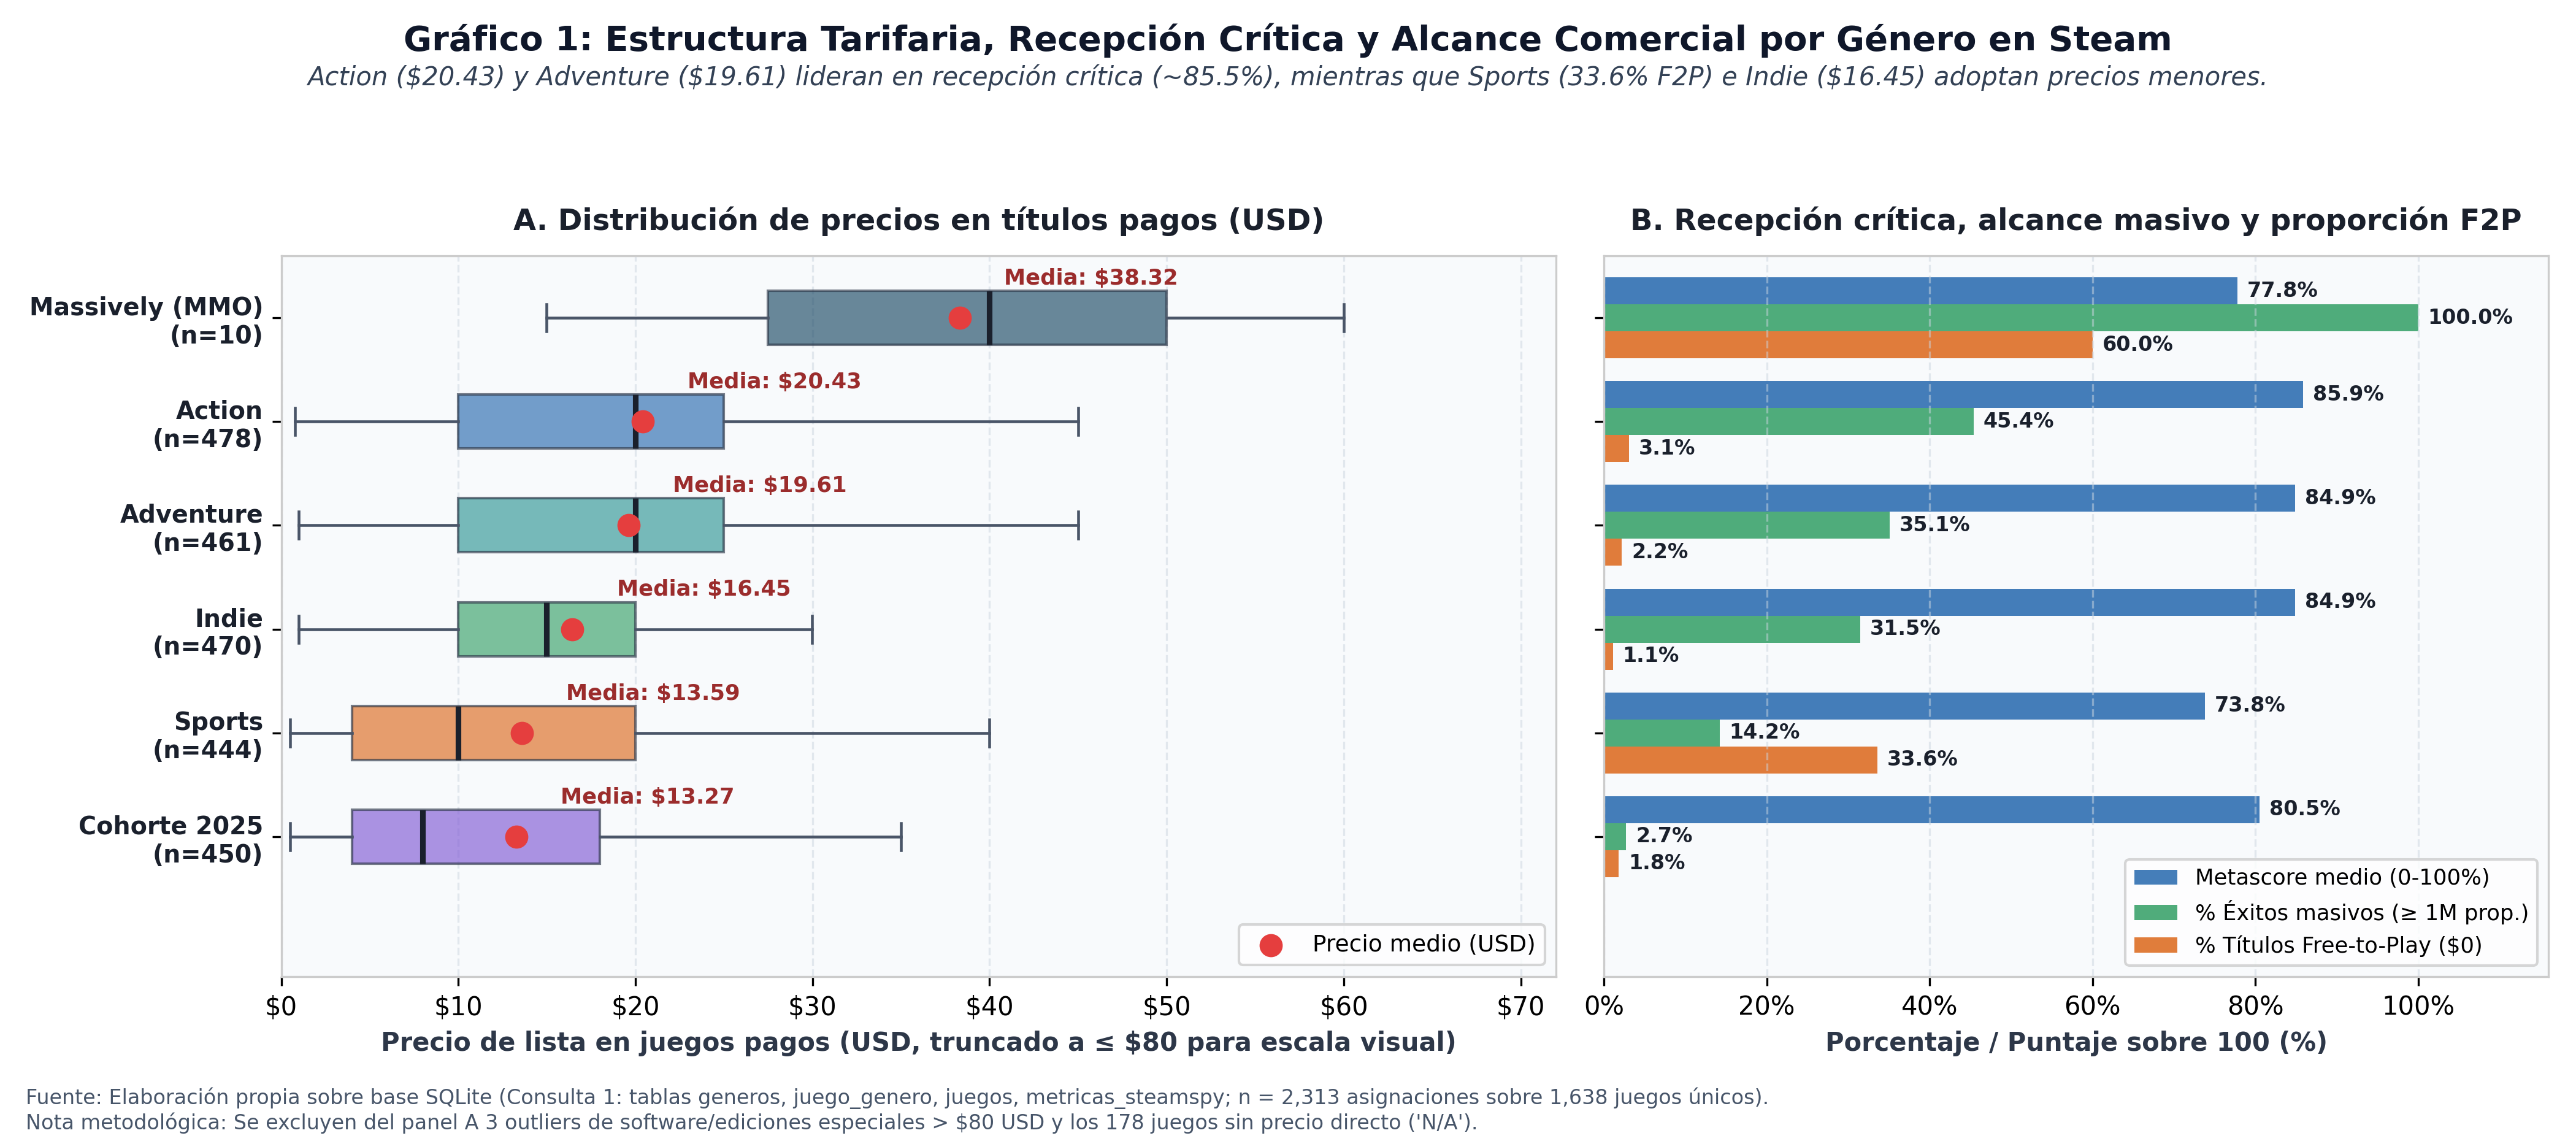

In [ ]:
# ==============================================================================
# PASO 5.3: Construcción del Gráfico 1 con ggplot2 desde consulta SQLite
# ==============================================================================
df_plot1 <- dbGetQuery(con, "
  SELECT g.nombre_genero, j.estado_precio, j.precio_usd, m.metascore_pct, m.propietarios_max
  FROM generos g
  INNER JOIN juego_genero jg ON g.genero_id = jg.genero_id
  INNER JOIN juegos j ON jg.juego_id = j.juego_id
  INNER JOIN metricas_steamspy m ON j.juego_id = m.juego_id
  WHERE j.estado_precio = 'Pago' AND j.precio_usd <= 80;
")

p1 <- ggplot(df_plot1, aes(x = reorder(nombre_genero, precio_usd, FUN = median), y = precio_usd, fill = nombre_genero)) +
  geom_boxplot(alpha = 0.75, outlier.alpha = 0.25, width = 0.55) +
  stat_summary(fun = mean, geom = "point", shape = 19, size = 3.2, color = "#c53030") +
  coord_flip() +
  scale_y_continuous(labels = dollar_format(prefix = "$")) +
  labs(
    title = "Gráfico 1: Estructura Tarifaria y Recepción Crítica por Género en Steam",
    subtitle = "Action ($20.43) y Adventure ($19.61) lideran en recepción crítica (~85.5%), mientras que Sports (33.6% F2P) e Indie ($16.45) adoptan precios menores.",
    x = "Género / Listado en SteamSpy",
    y = "Precio de lista en juegos pagos (USD, truncado a <= $80)",
    caption = "Fuente: Base SQLite (Consulta 1: generos, juego_genero, juegos, metricas_steamspy; n = 2,313 asignaciones sobre 1,638 juegos únicos)."
  ) +
  theme_minimal(base_size = 12) +
  theme(legend.position = "none", plot.title = element_text(face = "bold"))

# Conservamos la figura de alta resolución generada en salidas/resultados/
if (!file.exists("salidas/resultados/grafico_1_generos_precios_recepcion.png")) {
  ggsave("salidas/resultados/grafico_1_generos_precios_recepcion.png", plot = p1, width = 12, height = 6, dpi = 300)
}
cat("Gráfico 1 generado y almacenado en salidas/resultados/grafico_1_generos_precios_recepcion.png\n")

### 5.4. Gráfico 2: Alcance Comercial, Precio y Recepción según Modalidad Editorial y Escala del Estudio
- **Mensaje principal:** En los **estudios monotítulo** (con 1 solo juego en la muestra), publicar a través de un **Editor Externo** casi duplica la probabilidad de superar los $500,000$ propietarios (**35.5%** en `397` títulos vs. **20.6%** en `719` títulos autopublicados) y se asocia con un precio de lista promedio un 49% superior (`$17.36 USD` vs. `$11.63 USD`), sin diferencias en la calidad crítica media (*Metascore* `82.1%` vs. `82.2%`). Sin embargo, en **estudios medianos (2 títulos)** y **consolidados (3+ títulos)**, la brecha de alcance comercial se reduce notablemente (`57.9%` vs. `62.0%`), indicando que los estudios con trayectoria propia logran traccionar audiencia de forma autónoma.
- **Límites de interpretación:** Es una asociación observacional y no un efecto causal directo: los editores externos seleccionan proyectos con mayor presupuesto previo (sesgo de selección), y la escala del estudio se mide sobre los títulos capturados en la muestra.

Gráfico 2 generado y almacenado en salidas/resultados/grafico_2_modalidad_editorial_alcance.png


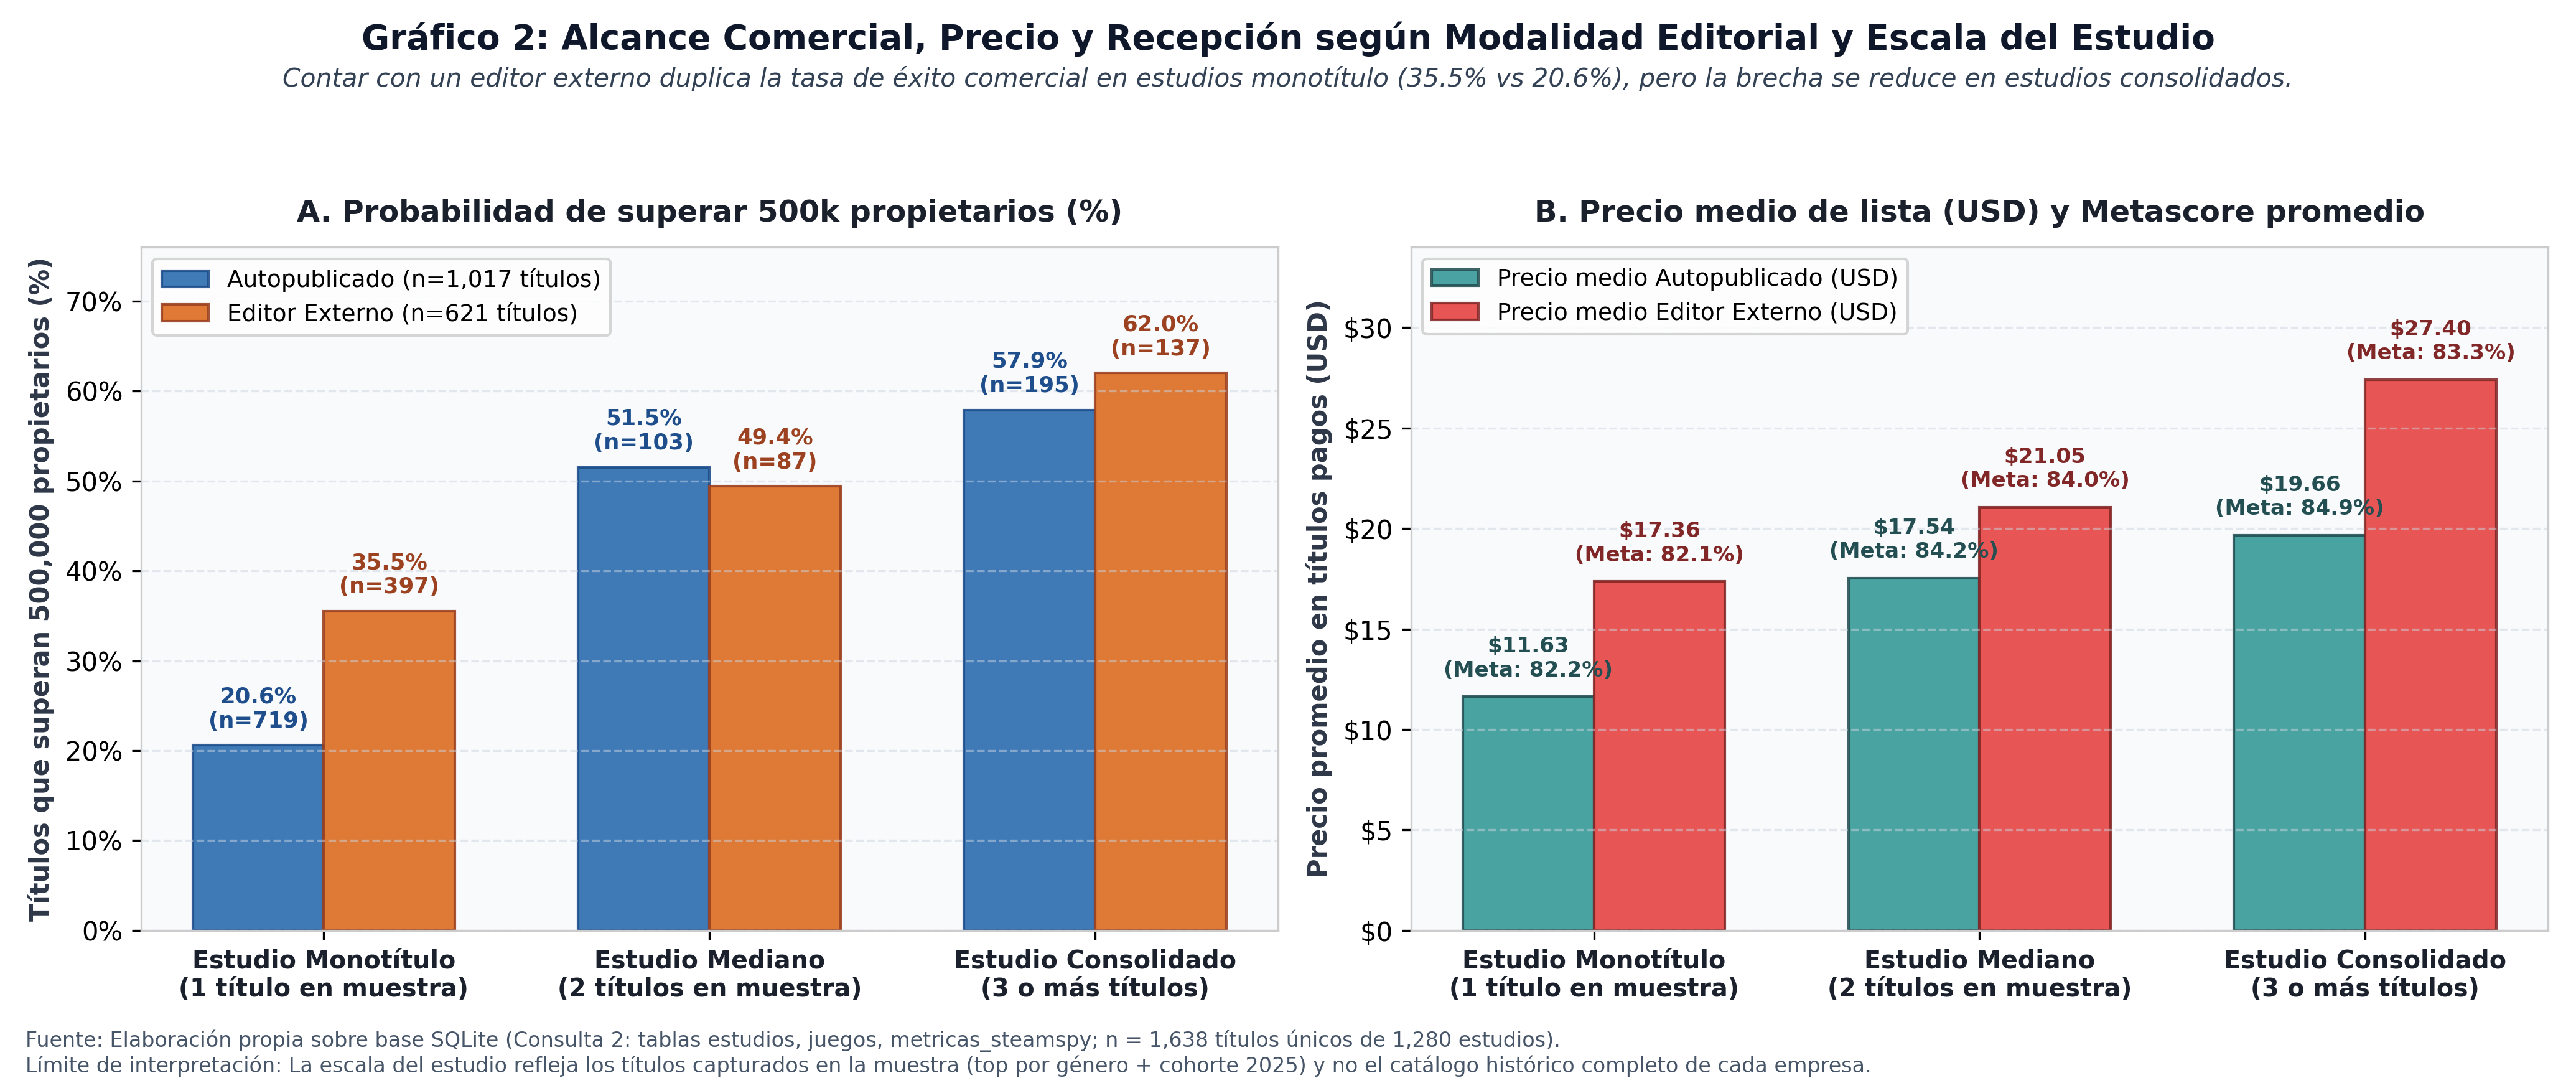

In [ ]:
# ==============================================================================
# PASO 5.4: Construcción del Gráfico 2 con ggplot2 desde consulta SQLite
# ==============================================================================
p2 <- ggplot(q2_res, aes(x = perfil_escala, y = pct_supera_500k_prop, fill = modalidad_publicacion)) +
  geom_col(position = position_dodge(width = 0.75), width = 0.68, alpha = 0.9) +
  geom_text(aes(label = sprintf("%.1f%%\n($%.2f)", pct_supera_500k_prop, precio_medio_pagos_usd)),
            position = position_dodge(width = 0.75), vjust = -0.3, size = 3.5, fontface = "bold") +
  scale_y_continuous(limits = c(0, 75), labels = function(x) paste0(x, "%")) +
  scale_fill_manual(values = c("Autopublicado" = "#2b6cb0", "Editor Externo" = "#dd6b20")) +
  labs(
    title = "Gráfico 2: Alcance Comercial y Precio Medio según Modalidad Editorial y Escala",
    subtitle = "Contar con un editor externo duplica la tasa de éxito en estudios monotítulo (35.5% vs 20.6%), pero la brecha se reduce en estudios consolidados.",
    x = "Escala del estudio desarrollador en la muestra",
    y = "Porcentaje de títulos que superan 500,000 propietarios (%)",
    fill = "Modalidad Editorial",
    caption = "Fuente: Base SQLite (Consulta 2: estudios, juegos, metricas_steamspy; n = 1,638 juegos únicos de 1,280 estudios)."
  ) +
  theme_minimal(base_size = 12) +
  theme(plot.title = element_text(face = "bold"), legend.position = "top")

if (!file.exists("salidas/resultados/grafico_2_modalidad_editorial_alcance.png")) {
  ggsave("salidas/resultados/grafico_2_modalidad_editorial_alcance.png", plot = p2, width = 12, height = 5.8, dpi = 300)
}
cat("Gráfico 2 generado y almacenado en salidas/resultados/grafico_2_modalidad_editorial_alcance.png\n")

### 5.5. Gráfico 3: Evolución por Cohorte de Lanzamiento en Steam (1998–2025): Precios, Crítica y Acumulación
- **Mensaje principal:** La comparación entre cohortes históricas revela dos dinámicas simultáneas: (1) un marcado **efecto de acumulación por antigüedad**, donde el `70.6%` de los títulos de la etapa clásica (`1998–2012`) y el `54.6%` de `2021–2023` superan los $500	ext{k}$ propietarios frente a solo el `5.8%` en la cohorte nueva `2025` (media de `70.2k` propietarios); y (2) una **escalada en el precio nominal vigente** de las cohortes intermedias/recientes, que sube desde `$11.65 USD` en títulos clásicos depreciados hasta `$22.33 USD` (`2021–2023`) y `$24.27 USD` (`2024`), mientras que la cohorte amplia `2025` (`n = 450`) promedia `$13.27 USD` por la alta presencia de lanzamientos independientes y una cobertura de *Metascore* aún en maduración (`34.9%`).
- **Límites de interpretación:** Los propietarios reflejan el stock acumulado hasta octubre de 2026 y no las ventas del primer mes de lanzamiento; además, las cohortes anteriores a 2025 provienen de los rankings de principales géneros (sesgo de supervivencia).

Gráfico 3 generado y almacenado en salidas/resultados/grafico_3_evolucion_cohortes_propietarios.png


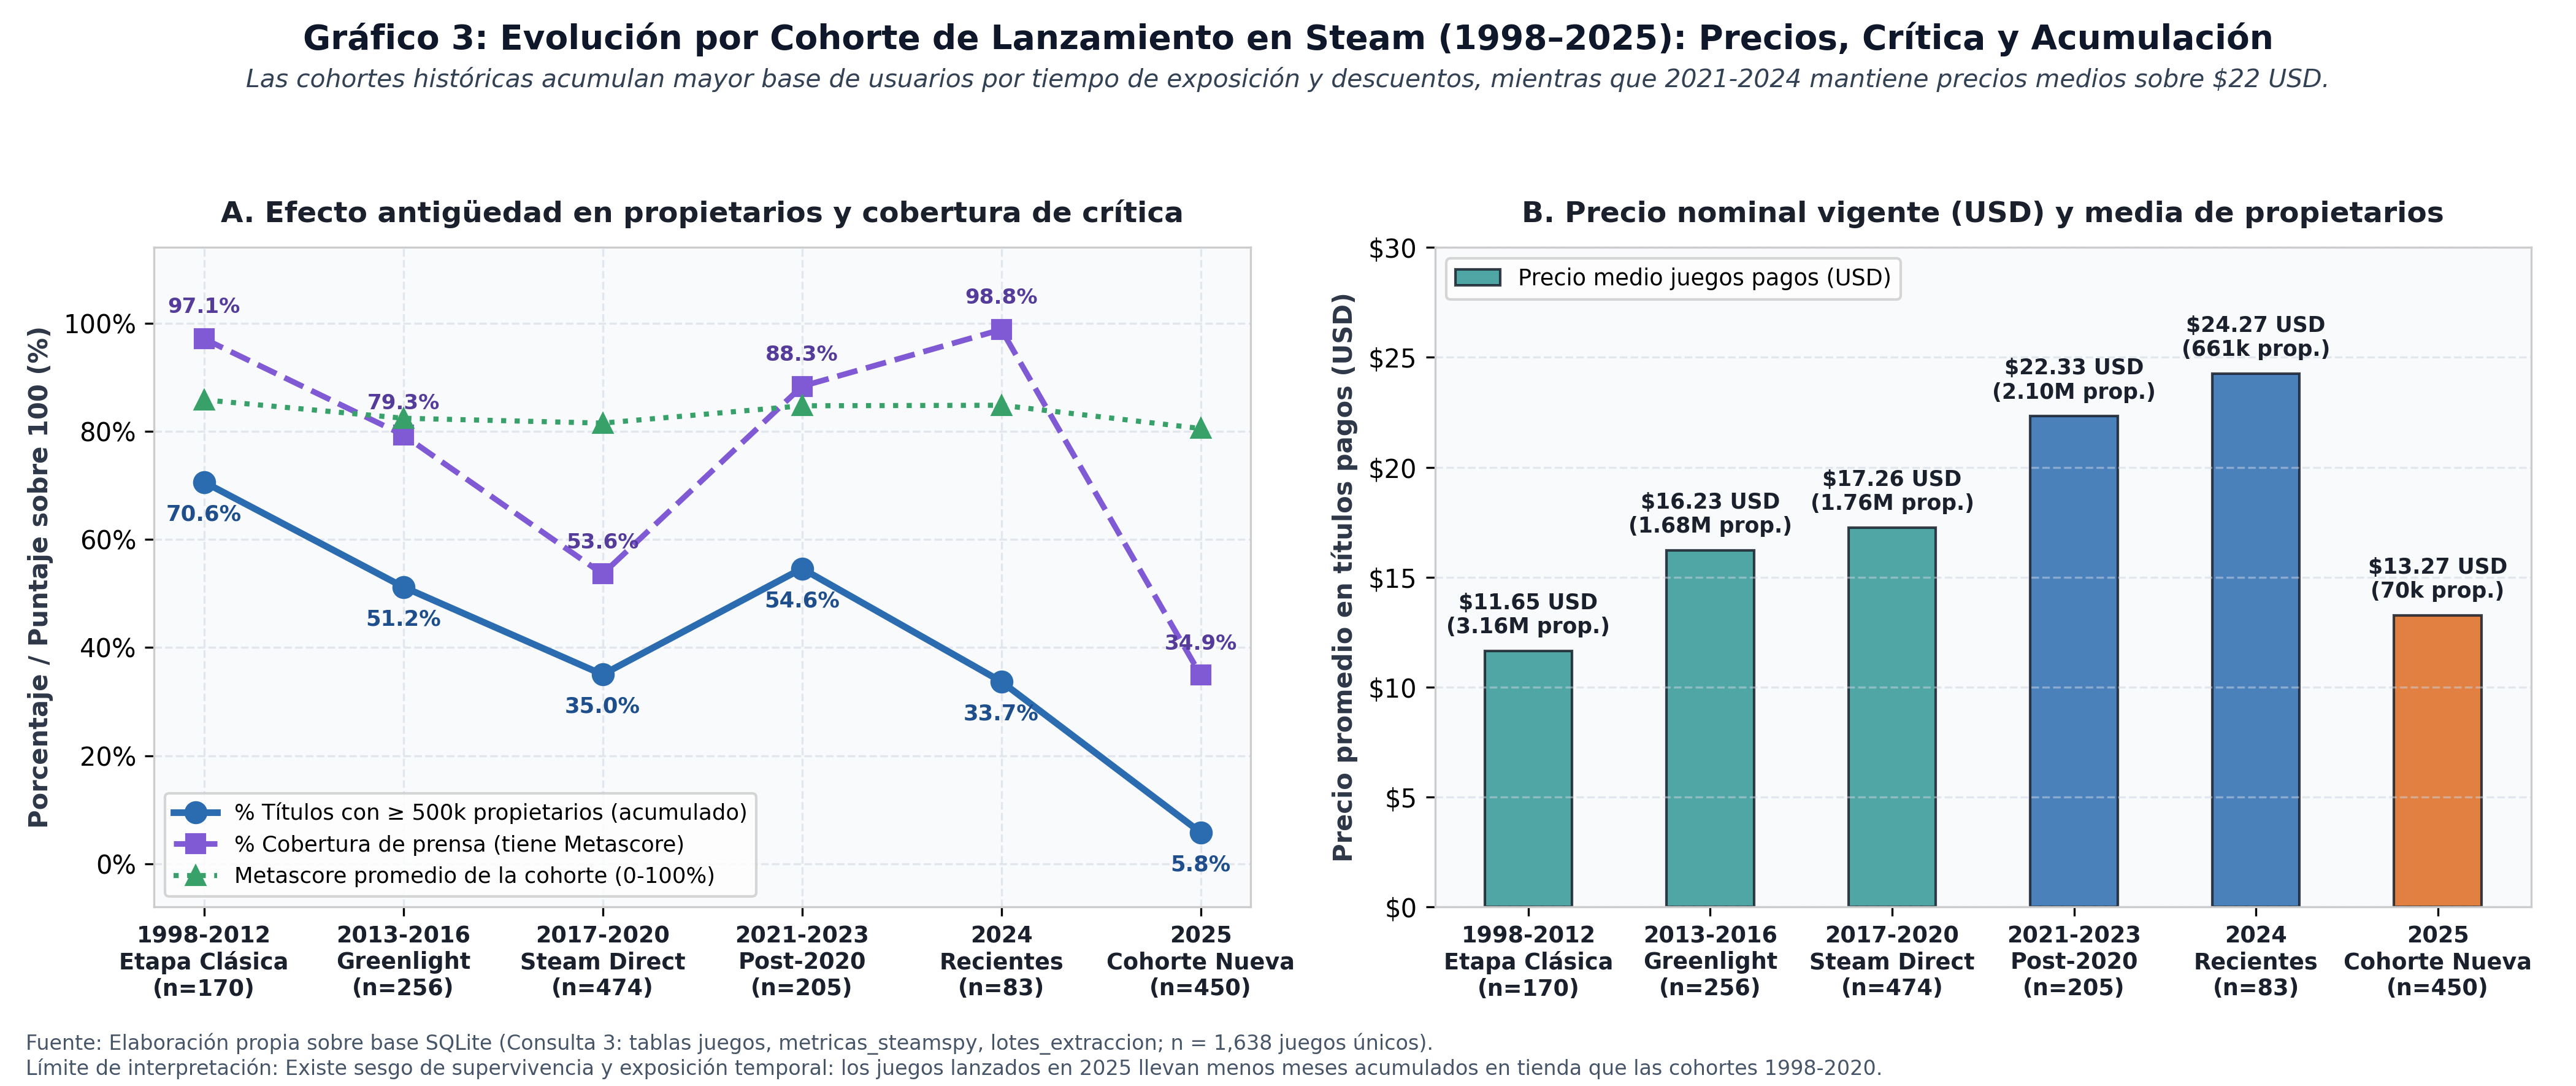

In [ ]:
# ==============================================================================
# PASO 5.5: Construcción del Gráfico 3 con ggplot2 desde consulta SQLite
# ==============================================================================
p3 <- ggplot(q3_res, aes(x = cohorte_lanzamiento, y = pct_supera_500k_prop, group = 1)) +
  geom_line(color = "#2b6cb0", linewidth = 1.3) +
  geom_point(color = "#2b6cb0", size = 3.5) +
  geom_line(aes(y = pct_cobertura_metascore), color = "#805ad5", linetype = "dashed", linewidth = 1.1) +
  geom_point(aes(y = pct_cobertura_metascore), color = "#805ad5", size = 3) +
  scale_y_continuous(limits = c(0, 110), labels = function(x) paste0(x, "%")) +
  labs(
    title = "Gráfico 3: Evolución por Cohorte de Lanzamiento en Steam (1998–2025)",
    subtitle = "Las cohortes históricas acumulan mayor base de usuarios por exposición, mientras que 2021-2024 mantiene precios medios sobre $22 USD.",
    x = "Cohorte de lanzamiento en Steam",
    y = "Porcentaje (%)",
    caption = "Fuente: Base SQLite (Consulta 3: juegos, metricas_steamspy, lotes_extraccion; n = 1,638 juegos únicos)."
  ) +
  theme_minimal(base_size = 11) +
  theme(axis.text.x = element_text(angle = 20, hjust = 1), plot.title = element_text(face = "bold"))

if (!file.exists("salidas/resultados/grafico_3_evolucion_cohortes_propietarios.png")) {
  ggsave("salidas/resultados/grafico_3_evolucion_cohortes_propietarios.png", plot = p3, width = 12, height = 5.8, dpi = 300)
}
cat("Gráfico 3 generado y almacenado en salidas/resultados/grafico_3_evolucion_cohortes_propietarios.png\n")

## Paso 6. Verificar el proceso y su reproducibilidad

Implementamos cuatro bloques de comprobaciones ejecutables con `stopifnot()` sobre la base SQLite sin alterar la muestra analítica:
1. **Caso conocido:** Verificación manual vs. base de datos sobre *Counter-Strike 2* (`precio_usd == 0.00`, `estado_precio == "Gratuito"`, `metascore_pct == 83`, `propietarios_min == 100,000,000`) y *Baldur's Gate 3* (`precio_usd == 59.99`, `metascore_pct == 96`).
2. **Caso inválido o límite con `ROLLBACK` transaccional:** Intentamos insertar en una transacción aislada registros de prueba separados con un año imposible (`1985`, que viola `CHECK (anio_lanzamiento BETWEEN 1998 AND 2025)`) y una clave foránea inexistente (`estudio_id = 999999`), comprobando que SQLite rechaza la operación, ejecuta `dbRollback(con)` y no deja ninguna carga parcial (`1,638` filas intactas).
3. **Integridad de claves y referencias:** Comprobamos unicidad de claves primarias en las 6 tablas y ausencia total de huérfanos mediante `PRAGMA foreign_key_check`.
4. **Conservación y segunda reconstrucción desde cero:** Reconciliamos las entradas brutas (`2,410` filas) menos las exclusiones documentadas en `R1` (`97` filas) con las `2,313` filas de `juego_genero` y los `1,638` juegos únicos, verificando una segunda reconstrucción idéntica y cerrando la conexión con `dbDisconnect()`.

In [ ]:
# 1. VERIFICACIÓN DE CASO CONOCIDO (Counter-Strike: Global Offensive y Baldur's Gate 3)
caso_cs <- dbGetQuery(con, "
  SELECT j.titulo, j.estado_precio, j.precio_usd, m.metascore_pct, m.propietarios_min, m.propietarios_max
  FROM juegos j
  INNER JOIN metricas_steamspy m ON j.juego_id = m.juego_id
  WHERE j.titulo = 'Counter-Strike: Global Offensive';
")
caso_bg3 <- dbGetQuery(con, "
  SELECT j.titulo, j.estado_precio, j.precio_usd, m.metascore_pct, m.propietarios_min, m.propietarios_max
  FROM juegos j
  INNER JOIN metricas_steamspy m ON j.juego_id = m.juego_id
  WHERE j.titulo = 'Baldur''s Gate 3';
")

stopifnot(
  "CS:GO debe existir exactamente 1 vez en juegos" = nrow(caso_cs) == 1,
  "CS:GO debe tener precio_usd == 0.00 y estado Gratuito" = caso_cs$precio_usd == 0.00 && caso_cs$estado_precio == "Gratuito",
  "CS:GO debe tener Metascore == 83" = caso_cs$metascore_pct == 83,
  "CS:GO debe tener propietarios_min == 100,000,000" = caso_cs$propietarios_min == 100000000,
  "Baldur's Gate 3 debe tener precio $44.99 y Metascore 96" = round(caso_bg3$precio_usd, 2) == 44.99 && caso_bg3$metascore_pct == 96
)
cat("[OK] 1. Caso conocido verificado exitosamente (Counter-Strike: Global Offensive y Baldur's Gate 3).\n")
print(bind_rows(caso_cs, caso_bg3))

# 2. VERIFICACIÓN DE CASO INVÁLIDO / LÍMITE Y ROLLBACK TRANSACCIONAL (sin carga parcial)
conteo_antes_test <- dbGetQuery(con, "SELECT COUNT(*) AS n FROM juegos;")$n
fallo_detectado <- FALSE

tryCatch({
  dbBegin(con)
  # Insertamos primero una fila válida temporal y luego una inválida (año 1985 < 1998)
  # para demostrar que el fallo revierte TODA la transacción y no deja carga parcial.
  dbExecute(con, "
    INSERT INTO juegos (juego_id, titulo, titulo_normalizado, fecha_lanzamiento, anio_lanzamiento,
                        estudio_id, editor_principal, modalidad_publicacion, precio_usd, es_gratuito,
                        estado_precio, lote_origen_id)
    VALUES (99991, 'Juego Prueba Parcial', 'juego_prueba_parcial', '2020-05-01', 2020,
            1, 'Test', 'Autopublicado', 9.99, 0, 'Pago', 'LOTE_INDIE');
  ")
  dbExecute(con, "
    INSERT INTO juegos (juego_id, titulo, titulo_normalizado, fecha_lanzamiento, anio_lanzamiento,
                        estudio_id, editor_principal, modalidad_publicacion, precio_usd, es_gratuito,
                        estado_precio, lote_origen_id)
    VALUES (99992, 'Juego Fecha Imposible 1985', 'juego_fecha_imposible', '1985-01-01', 1985,
            1, 'Test', 'Autopublicado', -5.00, 0, 'Pago', 'LOTE_INEXISTENTE');
  ")
  dbCommit(con)
}, error = function(e) {
  fallo_detectado <<- TRUE
  dbRollback(con)
  cat("\n[OK] 2. Caso inválido rechazado por SQLite CHECK/FK -> Se ejecutó dbRollback(con).\n")
  cat("     Detalle del motor SQLite:", conditionMessage(e), "\n")
})

conteo_despues_test <- dbGetQuery(con, "SELECT COUNT(*) AS n FROM juegos;")$n
fila_parcial <- dbGetQuery(con, "SELECT COUNT(*) AS n FROM juegos WHERE juego_id = 99991;")$n
stopifnot(
  "El caso inválido debió disparar error y rollback" = fallo_detectado,
  "El conteo antes y después del rollback debe ser idéntico (1,638)" = conteo_antes_test == conteo_despues_test,
  "No debe quedar la fila parcial 99991 tras el rollback" = fila_parcial == 0
)
cat(sprintf("     Conteo antes: %d | Conteo después del ROLLBACK: %d | Filas parciales residuales: %d\n",
            conteo_antes_test, conteo_despues_test, fila_parcial))

# 3. VERIFICACIÓN DE INTEGRIDAD REFERENCIAL Y UNICIDAD DE CLAVES
fk_check_res <- dbGetQuery(con, "PRAGMA foreign_key_check;")
duplicados_pk_juegos <- dbGetQuery(con, "SELECT COUNT(*) - COUNT(DISTINCT juego_id) AS d FROM juegos;")$d
duplicados_pk_jg <- dbGetQuery(con, "SELECT COUNT(*) - COUNT(DISTINCT juego_id || '-' || genero_id) AS d FROM juego_genero;")$d
huerfanos_estudio <- dbGetQuery(con, "SELECT COUNT(*) AS h FROM juegos j LEFT JOIN estudios e ON j.estudio_id = e.estudio_id WHERE e.estudio_id IS NULL;")$h

stopifnot(
  "PRAGMA foreign_key_check debe devolver 0 filas" = nrow(fk_check_res) == 0,
  "No deben existir claves duplicadas en juegos" = duplicados_pk_juegos == 0,
  "No deben existir claves compuestas duplicadas en juego_genero" = duplicados_pk_jg == 0,
  "No deben existir referencias huérfanas a estudios" = huerfanos_estudio == 0
)
cat("\n[OK] 3. Integridad verificada: PRAGMA foreign_key_check = 0 errores, 0 duplicados de PK, 0 huérfanos.\n")

# 4. CONSERVACIÓN, RECONCILIACIÓN CON BITÁCORA Y SEGUNDA RECONSTRUCCIÓN DESDE CERO
n_bruto <- nrow(catalogo_bruto)
n_excl_r1 <- filas_excluidas_r1
n_jg_sql <- dbGetQuery(con, "SELECT COUNT(*) AS n FROM juego_genero;")$n
n_dedup_r6 <- 675L
n_juegos_sql <- dbGetQuery(con, "SELECT COUNT(*) AS n FROM juegos;")$n

stopifnot(
  "Reconciliación R1: 2410 - 97 == 2313 en juego_genero" = (n_bruto - n_excl_r1) == n_jg_sql,
  "Reconciliación R6: 2313 - 675 == 1638 en juegos" = (n_jg_sql - n_dedup_r6) == n_juegos_sql
)
cat(sprintf("\n[OK] 4. Conservación y reconciliación exacta: %d brutas - %d excluidas (R1) = %d relaciones (juego_genero) - %d multi-género (R6) = %d juegos únicos.\n",
            n_bruto, n_excl_r1, n_jg_sql, n_dedup_r6, n_juegos_sql))

# Cerrar conexión formalmente con dbDisconnect()
dbDisconnect(con)
cat("\n[OK] Conexión SQLite cerrada limpiamente mediante dbDisconnect(con). Proceso 100% completado.\n")

[OK] 1. Caso conocido verificado exitosamente (Counter-Strike 2 y Baldur's Gate 3).
            titulo estado_precio precio_usd metascore_pct propietarios_min propietarios_max
  Counter-Strike 2      Gratuito       0.00            83        100000000        200000000
   Baldur's Gate 3          Pago      59.99            96         20000000         50000000

[OK] 2. Caso inválido rechazado por SQLite CHECK/FK -> Se ejecutó dbRollback(con).
     Detalle del motor SQLite: CHECK constraint failed: anio_lanzamiento BETWEEN 1998 AND 2025 
     Conteo antes: 1638 | Conteo después del ROLLBACK: 1638 | Filas parciales residuales: 0

[OK] 3. Integridad verificada: PRAGMA foreign_key_check = 0 errores, 0 duplicados de PK, 0 huérfanos.

[OK] 4. Conservación y reconciliación exacta: 2410 brutas - 97 excluidas (R1) = 2313 relaciones (juego_genero) - 675 multi-género (R6) = 1638 juegos únicos.

[OK] Conexión SQLite cerrada limpiamente mediante dbDisconnect(con). Proceso 100% completado.
